[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anita-agasaveeran/Assignment4/blob/main/03_KDD_Canada_Electricity/notebooks/KDD_Canada_Electricity.ipynb)

# Is Canada's Grid Becoming Less Combustion-Dependent? Knowledge Discovery in Canadian Electricity Data
**CMPE 255 · Assignment 4 · Project 3 of 3**

This project follows the **KDD process** (Fayyad, Piatetsky-Shapiro & Smyth, 1996): domain understanding and goals → **Selection** → **Preprocessing** → **Transformation** → **Data mining** → **Interpretation / evaluation** → using the knowledge. A **front pass** first checks the data, fixes the preprocessing rules and freezes the holdouts.

*Data: [Canada Electricity: Generation and Trade](https://www.kaggle.com/datasets/hgultekin/canada-monthly-electricity-benchmark) (Habib Gultekin, 2026). Adapted from Statistics Canada, Tables 25-10-0015-01 and 25-10-0016-01 (reference periods 2008-01 to 2026-08), Statistics Canada Open Licence. This does not constitute an endorsement by Statistics Canada.*

## 0. Setup

In [1]:
import os, subprocess, sys
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/anita-agasaveeran/Assignment4.git"
if IN_COLAB:
    if not Path("/content/Assignment4").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/Assignment4"], check=True)
    PROJECT_DIR = Path("/content/Assignment4/03_KDD_Canada_Electricity")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "/content/Assignment4/requirements.txt", "ruptures>=1.1"], check=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_DIR / "src")); os.chdir(PROJECT_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from kddenergy import config as c
from kddenergy.data import load_generation, load_availability, load_backtest, generation_wide, thermal_series
c.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ATTRIBUTION = "Source: adapted from Statistics Canada, Tables 25-10-0015-01 and 25-10-0016-01. This does not constitute an endorsement by Statistics Canada."
print("Project dir:", PROJECT_DIR, "| pandas", pd.__version__)

Project dir: /Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/03_KDD_Canada_Electricity | pandas 3.1.0


---
# Front pass · Goals, data checks, preprocessing rules, frozen holdouts

> **Revision 2**, after critic round 1 (6/10; `critiques/frontpass_round1.md`). Main changes:
> - the 2016 break is now treated as a **reporting-coverage expansion**, with a frozen "2016+ only" rule;
> - K2 is reframed from "thermal share" to **non-emitting / combustion share**;
> - the first lead is restated on development data only;
> - the loaders enforce the seal;
> - per-goal acceptance rules and the K4 margin are pre-registered.

### F.1 Domain and goals (KDD step 0)
**Hypothetical audience:** energy analysts and policy staff who want evidence about how Canada's provincial power systems differ and change.

| Goal | Question | Pre-registered acceptance (validity) |
|---|---|---|
| K1 Archetypes | Which provinces behave alike (generation mix, seasonality, trade dependence)? | Cluster assignments from 2016–2024 features vs 2025–26 features: adjusted Rand index ≥ 0.7 (`config.K1_MIN_ARI`) |
| K2 Structural change | When did each province's **non-emitting share** (hydro + nuclear + wind + solar + tidal) or **combustion share** change? Did the grid get *less combustion-dependent*? | A change point found on 2016–2024 data at **province level**: post-change direction persists in 2025–26, and the date is stable to ±3 months under resampling |
| K3 Anomalies | Which months were unusual (droughts, cold snaps, outages)? | Precision ≥ 0.5 of flagged months against an **event catalogue compiled from public sources before mining** |
| K4 Prediction | Can monthly availability be forecast better than seasonal naive? | Pooled WAPE on the sealed origins ≤ 0.90 × seasonal naive **and** better at both sealed origins |

**What "cleaner" can and can't mean here.** The data measures *sources* of generation, not emissions. A coal-to-gas switch, as in Alberta, cuts emissions without changing the combustion share. So K2 answers "less combustion-dependent?", and **emissions intensity is out of scope** unless external data (e.g. ECCC's National Inventory Report) is added. *Novelty* is judged against a named baseline, the Canada Energy Regulator's provincial energy profiles. *Usefulness* and *understandability* mean one chart and one sentence per finding.

### F.2 Data checks

*Structural checks (counts, status codes, additivity) use the full table, because they describe how the data is built, not what it says. Every value analysis after this uses data through 2024-12 only (sealed loaders).*

In [2]:
gen_all, avail_all = load_generation(allow_sealed=True), load_availability(allow_sealed=True)   # structure only
w_all = generation_wide(gen_all)
display(gen_all["source_status"].fillna("observed").value_counts().to_frame("status codes"))
tot_all = w_all[c.TOTAL_GEN].unstack("geography"); prov = tot_all.drop(columns="Canada"); full = prov.notna().all(axis=1)
print(f"Canada total = sum of provinces on all {full.sum()} complete months: {np.allclose(prov[full].sum(axis=1), tot_all.loc[full, 'Canada'])}")
cls = gen_all.pivot_table(index=["geography", "month", "generation_type"], columns="producer_class", values="generation_mwh")
both = cls.dropna()   # cells where utilities, industries and all-producers are all observed
print(f"utilities + industries = all producers on {len(both):,} fully observed cells: "
      f"{np.allclose(both.iloc[:, 0] + both.iloc[:, 1], both[c.TOTAL_PRODUCERS])}")
th_all = thermal_series(w_all)
ref = w_all[c.THERMAL_TECH_2008_2015].sum(axis=1, min_count=1).fillna(w_all[c.THERMAL_FUEL_2016_ON])
diff = (th_all - ref).dropna()
print(f"thermal residual vs StatCan thermal categories: {(diff.abs() <= 1).mean():.2%} of geo-months within 1 MWh; max |diff| = {diff.abs().max():,.0f} MWh")
exc = diff[diff.abs() > 1]
sealed_exc = exc[exc.index.get_level_values("month") > c.DISCOVERY_END]
display(exc[exc.index.get_level_values("month") <= c.DISCOVERY_END].rename("residual - reported (MWh)").to_frame())
print(f"(+ {len(sealed_exc)} exception(s) in sealed months, counted but not shown)")
neg = gen_all[gen_all["generation_mwh"] < 0]
print(f"negative generation values: {len(neg)} (net generation, e.g. station service during outages)")
display(neg.groupby(["geography", "generation_type"]).size().sort_values(ascending=False).head(6).to_frame("rows"))
print("availability balance residual != 0:", avail_all.loc[avail_all.balance_residual_mwh.abs() > 0, ["month", "geography", "balance_residual_mwh"]].to_dict("records"))

,status codes
source_status,
observed,58707
..,17955
x,114


Canada total = sum of provinces on all 224 complete months: True
utilities + industries = all producers on 15,483 fully observed cells: True
thermal residual vs StatCan thermal categories: 99.74% of geo-months within 1 MWh; max |diff| = 4,000 MWh


residual - reported (MWh)
geography     month                             
Alberta       2008-11                     4000.0
Canada        2008-11                     4000.0
              2015-07                      -14.0
              2022-03                     -300.0
New Brunswick 2015-07                      -12.0
Ontario       2022-03                     -300.0

(+ 2 exception(s) in sealed months, counted but not shown)
negative generation values: 652 (net generation, e.g. station service during outages)


rows
geography            generation_type                  
Prince Edward Island Conventional steam turbine    128
New Brunswick        Nuclear steam turbine         108
Prince Edward Island Combustion turbine            102
New Brunswick        Internal combustion turbine    70
Quebec               Combustion turbine             58
                     Nuclear steam turbine          46

availability balance residual != 0: [{'month': '2019-02', 'geography': 'British Columbia', 'balance_residual_mwh': 70931.0}, {'month': '2019-02', 'geography': 'Canada', 'balance_residual_mwh': 70931.0}, {'month': '2019-10', 'geography': 'Canada', 'balance_residual_mwh': -1.0}]


**What this shows:**
- **The totals add up.** Canada = Σ provinces (224/224 months); utilities + industries = all producers.
- **The thermal residual matches StatCan's reported thermal categories** within 1 MWh on all but 8 geo-months (max |diff| 4,000 MWh, in Alberta Nov 2008). They're kept; the development-period ones are listed and the 2 sealed-month ones only counted.
- **652 negative values are net generation** (e.g. station service at New Brunswick's Point Lepreau nuclear plant during its 2008–2012 refurbishment). They're kept as net generation, a Preprocessing decision recorded here.
- **The availability accounting balances** except for the documented Feb 2019 BC residual and a 1 MWh rounding residual.

#### The 2016 break is a reporting-coverage expansion plus a thermal reclassification

In [3]:
g = gen_all.assign(year=gen_all["month"].str[:4].astype(int))
x = g[g["year"].between(2014, 2017) & (g["geography"] != "Canada")]
cov = (x.assign(observed=x["generation_mwh"].notna())
         .groupby(["producer_class", "generation_type", "year"])["observed"].sum().unstack("year"))
cov = cov[cov.diff(axis=1).abs().sum(axis=1) > 0]
cov.index = cov.index.set_levels(cov.index.levels[0].str.replace("Electricity producers, ", "").str.replace("Total all classes of electricity producer", "all producers"), level=0)
display(cov.fillna(0).astype(int).rename_axis(columns="observed province-months"))
yr = w_all[[c.TOTAL_GEN, "Wind power turbine", "Solar"]].groupby([w_all.index.get_level_values(0), w_all.index.get_level_values(1).str[:4]]).sum(min_count=1)
step = (yr.xs("Canada", level=0).loc[["2014", "2015", "2016", "2017"]] / 1e6).round(2)
display(step.rename(columns=lambda s: s + " (TWh)"))
display((yr.xs("Alberta", level=0).loc[["2014", "2015", "2016", "2017"], [c.TOTAL_GEN]] / 1e6).round(1).rename(columns={c.TOTAL_GEN: "Alberta total (TWh)"}))

observed province-months                                               2014  \
producer_class     generation_type                                            
electric utilities Combustion turbine                                   124   
                   Conventional steam turbine                           117   
                   Hydraulic turbine                                    132   
                   Internal combustion turbine                          133   
                   Other types of electricity generation                  0   
                   Solar                                                 12   
                   Tidal power turbine                                   12   
                   Wind power turbine                                   116   
industries         Combustion turbine                                    36   
                   Conventional steam turbine                            96   
                   Hydraulic turbine                                     36   
                   Internal combustion turbine                           47   
                   Other types of electricity generation                  0   
                   Solar                                                  0   
                   Tidal power turbine                                    0   
                   Total all types of electricity generation            120   
                   Total electricity production from combustible f...     0   
                   Wind power turbine                                    12   
all producers      Combustion turbine                                   124   
                   Conventional steam turbine                           120   
                   Hydraulic turbine                                    132   
                   Internal combustion turbine                          144   
                   Other types of electricity generation                  0   
                   Solar                                                 12   
                   Tidal power turbine                                   12   
                   Wind power turbine                                   128   

observed province-months                                               2015  \
producer_class     generation_type                                            
electric utilities Combustion turbine                                   120   
                   Conventional steam turbine                           117   
                   Hydraulic turbine                                    132   
                   Internal combustion turbine                          132   
                   Other types of electricity generation                  0   
                   Solar                                                 12   
                   Tidal power turbine                                   12   
                   Wind power turbine                                   118   
industries         Combustion turbine                                    36   
                   Conventional steam turbine                            96   
                   Hydraulic turbine                                     36   
                   Internal combustion turbine                           38   
                   Other types of electricity generation                  0   
                   Solar                                                  0   
                   Tidal power turbine                                    0   
                   Total all types of electricity generation            120   
                   Total electricity production from combustible f...     0   
                   Wind power turbine                                    12   
all producers      Combustion turbine                                   120   
                   Conventional steam turbine                           123   
                   Hydraulic turbine             

generation_type,Total all types of electricity generation (TWh),Wind power turbine (TWh),Solar (TWh)
month,,,
2014,599.93,8.98,0.25
2015,592.76,8.85,0.26
2016,646.29,30.48,1.79
2017,649.38,30.91,2.05


generation_type,Alberta total (TWh)
month,
2014,65.7
2015,60.6
2016,79.2
2017,81.4


**Conclusion:**
- **What changed.** From January 2016, StatCan's survey reports producers it didn't cover before:
  - industrial wind, solar, tidal and "other" go from ≤ 12 reported province-months a year to 110–122 (some of them published zeros: industrial wind goes from 12 to 64 non-zero, utility solar from 12 to 35);
  - Canada's total generation rises 9% in one year, wind 3.4× and Alberta's total 31%;
  - in 2008–09, Manitoba and New Brunswick totals even exclude their suppressed wind;
  - separately, thermal output was *reclassified* from technology types to fuel types in 2016.
- **So 2008–2015 and 2016+ aren't comparable**, for thermal, wind, solar, totals *and* availability. The residual is additive *within* each era but can't bridge *across* them.
- **Frozen rule (`config.CONSISTENT_START = "2016-01"`):**
  - every cross-year comparison, cluster feature, trend, change point and anomaly baseline uses 2016-01 onward;
  - pre-2016 data is used only within its own era;
  - a 2016 change point is never reported as a discovery.

### F.3 First look at K2 (development data only: 2016-01 → 2024-12)

,non-emitting share,combustion share,non-renewable combustion share,hydro (TWh),nuclear (TWh),wind + solar (TWh)
month,,,,,,
2016,0.788,0.212,NaN,381.406,95.687,32.268
2017,0.800,0.200,NaN,390.753,95.743,32.955
2018,0.796,0.203,NaN,381.639,95.037,34.054
2019,0.794,0.206,NaN,377.641,95.469,35.254
2020,0.809,0.191,0.177,382.616,92.652,38.832
2021,0.802,0.198,0.183,376.987,87.376,38.921
2022,0.808,0.192,0.179,392.353,82.301,42.275
2023,0.793,0.206,0.191,359.286,84.566,44.325
2024,0.779,0.221,0.205,341.824,81.735,51.077


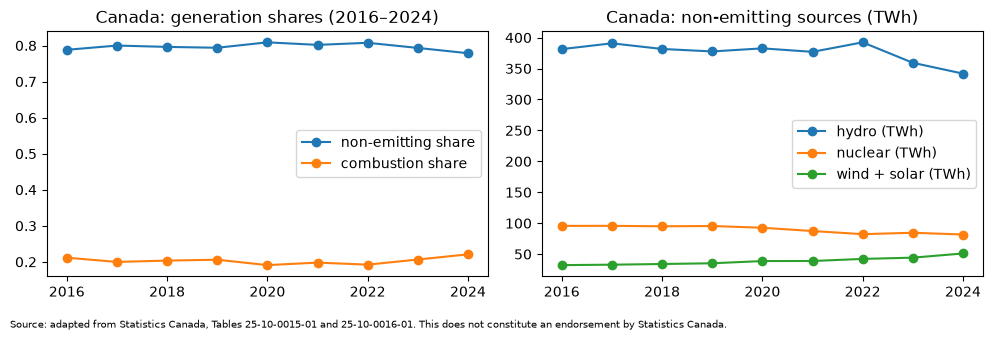

In [4]:
gen = load_generation()            # sealed: months <= 2024-12
w = generation_wide(gen)
can = w.xs("Canada", level="geography")
can = can[can.index >= c.CONSISTENT_START]
yearly = can.groupby(can.index.str[:4]).sum(min_count=1)
view = pd.DataFrame({
    "non-emitting share": yearly[c.NON_EMITTING].sum(axis=1) / yearly[c.TOTAL_GEN],
    "combustion share": thermal_series(w).xs("Canada", level="geography").loc[lambda s: s.index >= c.CONSISTENT_START].groupby(lambda m: m[:4]).sum() / yearly[c.TOTAL_GEN],
    "non-renewable combustion share": yearly["Total electricity production from non-renewable combustible fuels"] / yearly[c.TOTAL_GEN],
    "hydro (TWh)": yearly["Hydraulic turbine"] / 1e6, "nuclear (TWh)": yearly["Nuclear steam turbine"] / 1e6,
    "wind + solar (TWh)": (yearly["Wind power turbine"] + yearly["Solar"]) / 1e6,
})
display(view.round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
view[["non-emitting share", "combustion share"]].plot(ax=ax[0], marker="o", title="Canada: generation shares (2016–2024)")
view[["hydro (TWh)", "nuclear (TWh)", "wind + solar (TWh)"]].plot(ax=ax[1], marker="o", title="Canada: non-emitting sources (TWh)")
for a in ax: a.set_xlabel("")
fig.text(0.01, -0.04, ATTRIBUTION, fontsize=7)
plt.tight_layout(); plt.savefig(c.FIGURES_DIR / "f_canada_shares_2016_2024.png", dpi=150, bbox_inches="tight"); plt.show()

**The lead, restated (development data only).**
- **The share barely moved, then fell.** Canada's non-emitting share was roughly flat from 2016 to 2022, then fell in 2023–24 (the combustion share rose from about 19% to 22%).
- **What the table actually shows for 2022 → 2024** (corrected after critic round 2):
  - hydro fell 50.5 TWh (Quebec −30.7, BC −10.9, Manitoba −7.3; consistent with drought years in the public record);
  - that was mostly matched by **lower total generation** (−30.6 TWh; Quebec's total fell about as much as its hydro), not by more burning;
  - combustion rose 11.5 TWh, almost all in **Ontario** (+10.2);
  - nuclear was flat over 2022–24 (its decline came in 2020–22, when the share didn't move);
  - wind + solar grew 8.8 TWh.
  - So about half of the combustion-share rise is a shrinking denominator. K2's controls will include total generation and trade, not only hydro and nuclear.
- **The question for K2** is therefore not "did the grid get cleaner?" but: ***is the recent rise in combustion structural, or a hydro/nuclear availability dip that wind and solar can't yet cover?*** That's answered province by province in the KDD steps, with hydro and nuclear availability controlled.

**Disclosure:** the first draft of this front pass showed the *national* annual thermal share for 2025–2026. National-level K2 confirmation on 2025–26 is therefore treated as spent. Because Ontario drives about 90% of the national combustion change, **Ontario's** confirmation is treated as partly spent too and reported separately. The K2 verdict rests on the other provinces.

### F.4 Frozen holdouts (enforced in code)
| Goal | Development | Sealed / confirmation |
|---|---|---|
| K1–K3 | 2016-01 → **2024-12** (the consistent era) | **2025-01 → 2026-08**: patterns must persist (rules in F.1). National thermal/combustion share for 2025–26 already viewed (disclosed) |
| K4 | Forecast origins Dec 2018 → Dec 2023 (the dataset's own backtest design, 12-month horizon) | **Origins Dec 2024 and Dec 2025**, scored once |

- **How the seal is enforced:** `load_generation()`, `load_flows()` and `load_availability()` drop months after 2024-12 unless called with `allow_sealed=True`, and `load_backtest()` drops the sealed origins. Tests check this.
- **The dataset's published benchmark** (3.30% WAPE in `backtest_metrics.csv`) includes the sealed 2024-12 origin and the Canada aggregate, so it's never quoted.

### F.5 Feasibility for K4 (development origins only)

In [5]:
avail, bt = load_availability(), load_backtest()
A = avail.pivot(index="month", columns="geography", values="availability_mwh"); A.index = pd.PeriodIndex(A.index, freq="M")
geos = [g for g in A.columns if g != "Canada"]
rows = []
for o in c.DEV_ORIGINS:
    op = pd.Period(o, "M"); tgt = pd.period_range(op + 1, op + c.FORECAST_HORIZON, freq="M"); hist = A.loc[:op]
    for g in geos:
        y, h = A.loc[tgt, g], hist[g].dropna()
        if y.isna().any() or len(h) < 36:
            continue
        snaive = np.array([h.get(t - 12, np.nan) for t in tgt])
        avg3 = np.array([np.nanmean([h.get(t - 12 * k, np.nan) for k in (1, 2, 3)]) for t in tgt])
        growth = h.iloc[-12:].sum() / h.iloc[-24:-12].sum()
        rows.append({"origin": o, "geo": g, "y": y.to_numpy(), "snaive": snaive, "avg3": avg3, "avg3_growth": avg3 * np.sqrt(growth)})
# my seasonal naive must equal the dataset's own row-level forecasts (development origins, provinces/territories)
file_sn = bt[(bt.geography != "Canada") & bt.usable_prediction].set_index(["forecast_origin", "geography", "month"])["seasonal_naive_mwh"]
mine = pd.Series({(r["origin"], r["geo"], str(t)): v for r in rows for t, v in zip(pd.period_range(pd.Period(r["origin"], "M") + 1, periods=12, freq="M"), r["snaive"])})
common = mine.index.intersection(file_sn.index)
assert len(common) == len(mine) == len(file_sn), (len(common), len(mine), len(file_sn))
assert np.allclose(mine.loc[common], file_sn.loc[common]), "seasonal naive differs from the dataset's backtest"
print(f"seasonal naive matches the dataset's backtest row by row ({len(common)} forecasts)")
W = lambda rs, k: 100 * sum(np.abs(r["y"] - r[k]).sum() for r in rs) / sum(r["y"].sum() for r in rs)
methods = {"seasonal naive": "snaive", "3-year seasonal mean": "avg3", "3-year mean × √growth": "avg3_growth"}
per_origin = pd.DataFrame({name: {o: W([r for r in rows if r["origin"] == o], k) for o in c.DEV_ORIGINS} for name, k in methods.items()})
per_origin.loc["pooled"] = {name: W(rows, k) for name, k in methods.items()}
display(per_origin.round(2).rename_axis("origin (WAPE %)"))
rng = np.random.default_rng(c.SEED)
ratios = [W(s, "avg3_growth") / W(s, "snaive") for s in ([rows[i] for i in rng.integers(0, len(rows), len(rows))] for _ in range(1000))]
wins = np.mean([np.abs(r["y"] - r["avg3_growth"]).sum() < np.abs(r["y"] - r["snaive"]).sum() for r in rows])
print(f"WAPE ratio (3-year mean × √growth / seasonal naive): {W(rows, 'avg3_growth') / W(rows, 'snaive'):.3f}, "
      f"90% bootstrap interval {np.quantile(ratios, 0.05):.3f}-{np.quantile(ratios, 0.95):.3f}; better on {wins:.0%} of {len(rows)} province-origin pairs")

seasonal naive matches the dataset's backtest row by row (936 forecasts)


,seasonal naive,3-year seasonal mean,3-year mean × √growth
origin (WAPE %),,,
2018-12,3.25,3.34,3.29
2019-12,3.90,3.92,3.93
2020-12,4.24,3.75,3.78
2021-12,4.56,4.49,4.19
2022-12,4.52,3.57,3.65
2023-12,4.03,3.64,3.46
pooled,4.08,3.78,3.71


WAPE ratio (3-year mean × √growth / seasonal naive): 0.910, 90% bootstrap interval 0.862-0.961; better on 69% of 78 province-origin pairs


**Feasibility verdict (K4):**
- **The benchmark is reproduced row by row** (assert). 4.08% is the dataset's seasonal naive on these 6 development origins × 13 provinces and territories; the published 3.30% also includes the sealed origin and the Canada aggregate.
- **A trivial 3-year seasonal mean with a growth adjustment is about 9% better when pooled**, but not at every origin. The bootstrap interval is shown above. So the pre-registered K4 margin (≤ 0.90×, and better at both sealed origins) is a real test, not a formality.
- *Caveat:* the data is StatCan's latest revised vintage, not what was known in real time, so backtests can look slightly better than live forecasting would.
- **K1–K3:** the data supports them within the consistent era (2016–2024: 108 months × 13 geographies), with trade flows by partner available for net-import ratios.

---
# KDD 1 · Selection

**Target data: what goes into the mining steps, and what stays out.**

| Dimension | Selected | Excluded, and why |
|---|---|---|
| Geographies | 10 provinces + 3 territories (`config.GEOS`) | The `Canada` aggregate (it equals Σ provinces; adding it would double-count). Used only for national context |
| Period | 2016-01 → 2024-12 for discovery; 2025-01 → 2026-08 sealed for confirmation | 2008–2015: a different reporting coverage (front pass F.2, `CONSISTENT_START`) |
| Producer class | *Total all classes of electricity producer* | Utilities / industries separately (they add up to the total; front pass) |
| Generation types | Total, hydro, nuclear, wind, solar, tidal, other, **combustible fuels total** | 2008–15 thermal technology types (not reported in 2016+); non-renewable vs biomass split (only 2020+, 56% coverage in the era) |
| Flow components | Total generation (flows table), total receipts / deliveries, receipts from / deliveries to other provinces, purchased receipts from / deliveries to the US, availability | Firm / non-firm delivery splits and "other receipts from the US": `..` (unavailable) for every month in 2016+ |

The selection is code (`kddenergy.selection.build_panel`), so `refresh.py` rebuilds exactly the same target dataset from a new release.

In [6]:
from kddenergy.selection import build_panel
from kddenergy.preprocess import missing_report, clean, integration_checks, identity_exceptions, load_event_catalogue, catalogue_months, catalogue_sha256
from kddenergy import transform as T
raw = build_panel()                      # sealed loaders: months <= 2024-12
print(f"target dataset: {raw.shape[0]:,} geo-months ({raw.index.get_level_values('geography').nunique()} geographies x "
      f"{raw.index.get_level_values('month').nunique()} months) x {raw.shape[1]} series")
print("months:", raw.index.get_level_values("month").min(), "->", raw.index.get_level_values("month").max())
miss = missing_report(raw)
display((miss[miss.columns[miss.any()]].rename(index=c.ABBR) * 100).round(0).astype(int).T.rename_axis("% missing"))

target dataset: 1,404 geo-months (13 geographies x 108 months) x 16 series
months: 2016-01 -> 2024-12


geography,NL,PE,NS,NB,QC,ON,MB,SK,AB,BC,YT,NT,NU
% missing,,,,,,,,,,,,,
nuclear,100,100,100,0,100,0,100,100,100,100,100,100,100
tidal,0,0,0,0,100,100,100,100,100,0,100,100,100
other,0,0,0,0,0,0,0,0,0,0,0,100,100
receipts,0,0,0,0,0,0,0,0,0,0,100,100,100
deliveries,0,0,0,0,0,0,0,0,0,0,100,100,100
rec_prov,0,0,0,0,0,0,0,0,0,0,100,100,100
del_prov,0,0,0,0,0,0,0,0,0,0,100,100,100
rec_us,0,100,0,0,0,0,0,0,0,0,100,100,100
del_us,0,100,0,0,0,0,0,0,0,0,100,100,100


**What the missingness table says:** every gap is a *whole series* that a geography doesn't publish. There are no scattered holes inside reported series in 2016–2024:
- no nuclear outside Ontario and New Brunswick; tidal only in Nova Scotia (and zeros elsewhere);
- the three territories publish **no trade rows at all**: they're isolated grids;
- PEI has no direct US interconnection, so it has no US rows.

Those are *structural zeros*, decided in Preprocessing below, not values to impute.

---
# KDD 2 · Preprocessing (cleaning + integration)

Decisions, in order:
1. **Status codes → missing** (done in the loaders: `..` and `x` cells are `NaN`).
2. **Structural zeros:** a series a geography never publishes means "no such plant / interconnection" → 0. Missing cells *inside* a published series would stay missing; there are none in the era.
3. **Negative generation is kept** as net generation (front pass).
4. **Integration:** the generation table (25-10-0015-01) is joined to the flows table (25-10-0016-01) on geography × month. The two tables' totals must agree, the parts must add up to the totals, and the accounting identity generation + receipts − deliveries = availability must hold.
5. **Residuals are flagged, not fixed** (BC Feb 2019).
6. **Data-break register:** a coverage change found here is recorded in `config.DATA_BREAKS` *before* mining.
7. **The K3 event catalogue is compiled and frozen here**, before any anomaly is mined.

In [7]:
panel, decisions = clean(raw)
display(decisions)
print("missing cells after cleaning:", int(panel.isna().sum().sum()))
display(integration_checks(panel).to_frame("integration check").style.format("{:,.0f}"))
display(identity_exceptions(panel))

,column,action,geographies
0,nuclear,structural zero (no series published),"AB, BC, MB, NL, NS, NT, NU, PE, QC, SK, YT"
1,tidal,structural zero (no series published),"AB, MB, NT, NU, ON, QC, SK, YT"
2,other,structural zero (no series published),"NT, NU"
3,receipts,structural zero (no series published),"NT, NU, YT"
4,deliveries,structural zero (no series published),"NT, NU, YT"
5,rec_prov,structural zero (no series published),"NT, NU, YT"
6,del_prov,structural zero (no series published),"NT, NU, YT"
7,rec_us,structural zero (no series published),"NT, NU, PE, YT"
8,del_us,structural zero (no series published),"NT, NU, PE, YT"


missing cells after cleaning: 0


,integration check
geo-months,"1,404"
max |generation table - flows table|,0
geo-months with |availability identity residual| > 1,1
max |availability identity residual|,"70,931"
max |types sum - total generation|,300
max |receipt parts - total receipts|,0
max |delivery parts - total deliveries|,0


,,residual_mwh
geography,month,
British Columbia,2019-02,70931.0


**Integration verdict:**
- **The two StatCan tables agree exactly** on total generation in all 1,404 geo-months.
- **The parts add up:** provincial + US receipts = total receipts and provincial + US deliveries = total deliveries, both exactly. Generation types sum to the total within 300 MWh.
- **The accounting identity holds** everywhere except **BC, Feb 2019** (+70,931 MWh), which is flagged and kept as published. Availability is StatCan's published figure, not a value derived from the identity.

#### A coverage break inside the era: Nunavut's industrial producers (found before mining)

In [8]:
gen_cls = load_generation()
nu = (gen_cls[(gen_cls.geography == "Nunavut") & (gen_cls.generation_type == c.TOTAL_GEN) & gen_cls.month.between("2024-05", "2024-12")]
      .pivot(index="month", columns="producer_class", values="generation_mwh").rename(columns=lambda s: s.replace("Electricity producers, ", "")))
display(nu.astype(int))
nl = (gen_cls[(gen_cls.geography == "Newfoundland and Labrador") & (gen_cls.generation_type == "Hydraulic turbine") & gen_cls.month.between("2020-11", "2021-04")]
      .pivot(index="month", columns="producer_class", values="generation_mwh").rename(columns=lambda s: s.replace("Electricity producers, ", "")))
display((nl / 1e3).round(0).rename_axis("NL hydro (GWh)"))
print("data-break register:", c.DATA_BREAKS, "| break windows:", c.BREAK_WINDOWS)

producer_class,electric utilities,industries,Total all classes of electricity producer
month,,,
2024-05,15231,18,15249
2024-06,13881,12,13893
2024-07,13925,17,13942
2024-08,14465,13,14478
2024-09,14679,7,14686
2024-10,16247,14423,30670
2024-11,17073,15207,32280
2024-12,18272,15765,34037


producer_class,electric utilities,industries,Total all classes of electricity producer
NL hydro (GWh),,,
2020-11,3350.0,NaN,3350.0
2020-12,4369.0,NaN,4369.0
2021-01,4522.0,NaN,4522.0
2021-02,4008.0,56.0,4064.0
2021-03,4311.0,65.0,4376.0
2021-04,3235.0,66.0,3301.0


data-break register: {'Nunavut': '2024-10'} | break windows: {'Newfoundland and Labrador': ('2021-01', '2021-03')}


- **Nunavut's total generation doubles in October 2024** because **industrial producers appear** (≈ 0 → ≈ 14 GWh a month). Utility generation keeps its usual seasonal path. That's a reporting-coverage change (e.g. on-site mine generation now being counted), not a power-system event.
- **Newfoundland and Labrador: a smaller step of the same kind** (found by critic round 1). Industrial hydro is first reported in **2021-02** (+56–67 GWh a month, about 1.5% of NL generation), while utility hydro is unchanged.
- **Not a break, a real change:** Nova Scotia's industrial generation collapses from 2020 (306 GWh in 2019 → 4 GWh in 2022), consistent with the Northern Pulp mill closure (January 2020). It's kept as data. Industrial closures are out of the K3 catalogue's scope (see below).
- *Correction (critic round 1):* an earlier draft said no other break exists. That was wrong for NL.
- **Decisions (registered before mining):**
  - Nunavut from 2024-10 onward is excluded from K3 flagging and scoring.
  - NL 2021-01 → 2021-03 is excluded too, because a level step distorts STL residuals only around the break.
  - Nunavut is about **0.04%** of 2024 availability across the 13 geographies (corrected from 0.003%), so K1 (shares) and K4 (pooled WAPE) are essentially unaffected.

#### K3 event catalogue (frozen before mining)
`data/external/event_catalogue.csv`: public-record events that could plausibly make a geography's monthly data unusual (storms, cold snaps, heat, wildfires, drought, the COVID-19 lockdown). Its SHA-256 is fixed in `config.K3_CATALOGUE_SHA256`, and the loader refuses to read a changed file. **Revision 2 (after critic round 1, before any mining):**
- E32 (Quebec drought) starts in 2023-05 instead of 2023-01;
- the February 2021 and December 2022 Prairie cold outbreaks are added;
- drought end dates are marked as truncated at the window edge;
- plant outages, commissioning and industrial closures are declared out of scope.

The hash was updated. **Caveat:** it was compiled from the analyst's knowledge of public reporting at month level, not checked line by line against primary sources (`data/external/README.md`).

In [9]:
cat_dev = load_event_catalogue("discovery")
print("catalogue SHA-256:", catalogue_sha256()); print(f"{len(cat_dev)} discovery-period events (+ {len(load_event_catalogue(None)) - len(cat_dev)} confirmation-period events, used only after unsealing)")
display(cat_dev.groupby("event_type").agg(events=("event_id", "size"), geographies=("geography", lambda s: ", ".join(sorted(set(s.map(c.ABBR)))))))
from kddenergy.mining import eligible_mask
eligible = list(panel.index[eligible_mask(panel.index)])
covered = catalogue_months(cat_dev, window=c.K3_MATCH_MONTHS)
base_rate = np.mean([gm in covered for gm in eligible])
print(f"base rate: {base_rate:.1%} of {len(eligible):,} eligible geo-months lie within +/-{c.K3_MATCH_MONTHS} month of a catalogued event")
cov_geo = pd.Series({c.ABBR[g]: np.mean([(g, m) in covered for gg, m in eligible if gg == g]) for g in c.GEOS})
print("coverage by geography:", (cov_geo * 100).round(0).astype(int).to_dict())

catalogue SHA-256: ee336e9b5e7c57829f92b229eaa7b1e5aaa6ad92feeccd0542af0a905785a22b
40 discovery-period events (+ 4 confirmation-period events, used only after unsealing)


,events,geographies
event_type,,
cold,11,"AB, MB, QC, SK"
drought,4,"BC, MB, QC"
flood,1,BC
heat,1,BC
pandemic,10,"AB, BC, MB, NB, NL, NS, ON, PE, QC, SK"
storm,10,"NL, NS, ON, PE, QC"
wildfire,3,"AB, NT"


base rate: 13.2% of 1,398 eligible geo-months lie within +/-1 month of a catalogued event
coverage by geography: {'NL': 7, 'PE': 9, 'NS': 9, 'NB': 4, 'QC': 31, 'ON': 9, 'MB': 35, 'SK': 15, 'AB': 21, 'BC': 28, 'YT': 0, 'NT': 4, 'NU': 0}


**K3 rule made operational** (critic round 2 item N4, revised after KDD critic round 1), written into `config.py` before mining:
- **Flag budget:** the top 2% of eligible geo-months.
- **Match:** same geography, within ±1 month of an event.
- **Primary score: event-level precision.** Each catalogue event can credit at most one flag, so a detector can't collect hits by firing repeatedly inside one long drought.
- **Null model:** each geography's flags are *circularly shifted* within that geography (1,000 shifts). This keeps how many flags each geography gets, and so absorbs the very uneven coverage (MB 35%, QC 31%, BC 28% covered; YT and NU 0%).
- **Acceptance:** event-level precision ≥ 0.5 **and** permutation p ≤ 0.05.
- **Secondary:** flag-level precision and lift over the base rate. Lift can't bind here: at the 13.2% base rate, precision 0.5 already means lift ≈ 3.8.
- **Edge years** 2016 and 2024 have less STL power and are reported separately.
- **Confirmation (2025–26):** one-sided STL (fit up to month *t* only), with the Isolation Forest and its score threshold frozen and no re-ranking.

---
# KDD 3 · Transformation

Turn the clean panel into the representations each mining goal needs (`kddenergy.transform`):

| Output | Definition | Used by |
|---|---|---|
| Mix shares | hydro, nuclear, wind + solar, combustion, non-emitting ÷ total generation | K1, K2 |
| Trade ratios | net-import ratio (receipts − deliveries) ÷ availability; trade intensity (receipts + deliveries) ÷ availability; US net-export ratio | K1, K3 |
| Seasonality | availability calendar-month climatology → winter/summer ratio (Dec–Feb ÷ Jun–Aug) and amplitude (max − min) ÷ mean | K1 |
| **Balanced feature vectors** | one row per geography: each series is first averaged *by calendar month*, then the shares and ratios are computed from that typical year. A 20-month window (Jan–Aug twice) then weighs like a full year (critic N5) | K1 |
| Deseasonalized combustion share | monthly share − its 2016–2024 calendar-month mean | K2 |
| STL residual z-scores | robust STL (period 12) per geography and series (log availability, log generation, net-import ratio); z = residual ÷ 1.4826·MAD | K3 |
| Availability series | monthly MWh, 2016-01 onward only (K4 training window, critic N9) | K4 |

In [10]:
feat = T.add_features(panel)
X_dev = T.cluster_features(panel, c.CONSISTENT_START, c.DISCOVERY_END)   # config.K1_FEATURES (seasonal_amplitude dropped)
display(X_dev.rename(index=c.ABBR).style.format("{:.3f}").background_gradient(axis=0, cmap="Blues").set_caption("K1 feature vectors, 2016-01..2024-12 (calendar-month balanced)"))
c.PROCESSED.mkdir(parents=True, exist_ok=True)
panel.to_csv(c.PROCESSED / "panel_2016_2024.csv"); X_dev.to_csv(c.PROCESSED / "k1_features_2016_2024.csv")

,hydro_share,nuclear_share,windsolar_share,combustion_share,net_import_ratio,trade_intensity,us_net_export_ratio,winter_summer_ratio
geography,,,,,,,,
NL,0.959,0.000,0.004,0.037,-2.861,2.874,0.127,1.691
PE,0.000,0.000,0.986,0.014,0.607,0.977,0.000,1.305
NS,0.092,0.000,0.129,0.778,0.115,0.128,-0.014,1.400
NB,0.221,0.324,0.059,0.397,0.027,0.604,0.147,1.556
QC,0.939,0.000,0.051,0.010,0.009,0.317,0.101,1.510
ON,0.246,0.552,0.093,0.109,-0.092,0.195,0.112,0.999
MB,0.970,0.000,0.027,0.003,-0.306,0.408,0.259,1.405
SK,0.136,0.000,0.047,0.814,0.012,0.063,0.009,1.156
AB,0.027,0.000,0.094,0.878,0.022,0.052,-0.010,1.078


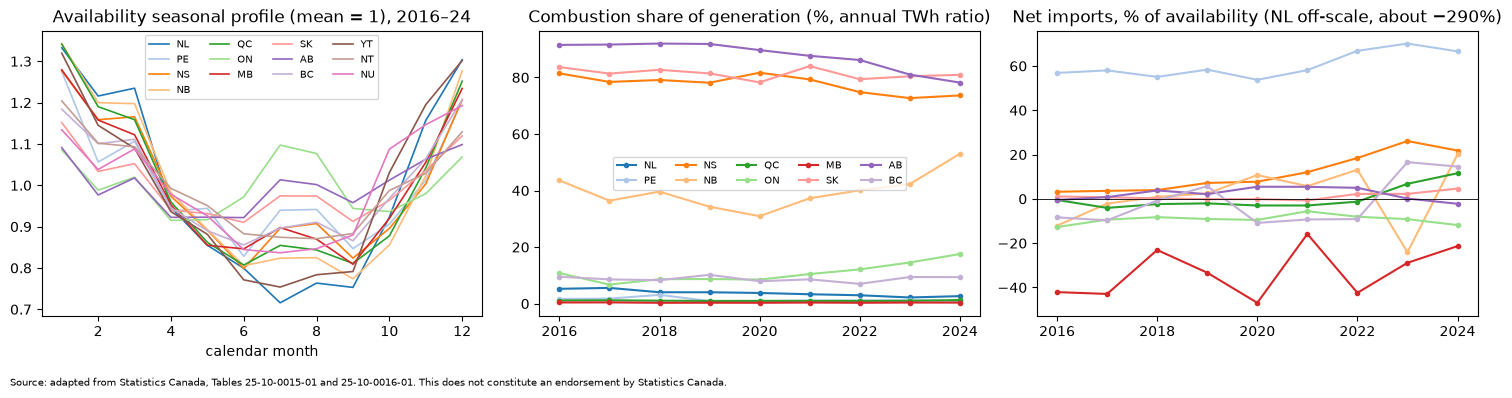

In [11]:
prof = T.seasonal_profiles(panel, c.CONSISTENT_START, c.DISCOVERY_END)
yr_sums = panel[["combustion", "gen_total"]].groupby([panel.index.get_level_values(0), panel.index.get_level_values(1).str[:4]]).sum()
share_y = (yr_sums["combustion"] / yr_sums["gen_total"]).rename("combustion_share").to_frame()   # ratio of annual sums
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cols = dict(zip(c.GEOS, plt.cm.tab20(np.linspace(0, 1, 20))[:13]))
for g in c.GEOS:
    ax[0].plot(range(1, 13), prof.loc[g], label=c.ABBR[g], lw=1.2, color=cols[g])
ax[0].set(title="Availability seasonal profile (mean = 1), 2016–24", xlabel="calendar month"); ax[0].legend(ncol=4, fontsize=7)
(share_y["combustion_share"].unstack(0)[c.PROVINCES] * 100).rename(columns=c.ABBR).plot(ax=ax[1], marker=".", color=[cols[g] for g in c.PROVINCES], title="Combustion share of generation (%, annual TWh ratio)")
ax[1].legend(ncol=5, fontsize=7); ax[1].set_xlabel("")
(feat["net_import_ratio"].groupby([feat.index.get_level_values(0), feat.index.get_level_values(1).str[:4]]).mean().unstack(0)[c.PROVINCES[1:]] * 100
 ).rename(columns=c.ABBR).plot(ax=ax[2], marker=".", color=[cols[g] for g in c.PROVINCES[1:]], title="Net imports, % of availability (NL off-scale, about −290%)", legend=False)
ax[2].axhline(0, color="k", lw=0.6); ax[2].set_xlabel("")
fig.text(0.01, -0.03, ATTRIBUTION, fontsize=7); plt.tight_layout()
plt.savefig(c.FIGURES_DIR / "t_profiles_shares_trade.png", dpi=150, bbox_inches="tight"); plt.show()

deseasonalized combustion share: monthly s.d. by province (percentage points)


geography,NL,PE,NS,NB,QC,ON,MB,SK,AB,BC
s.d. (pp),1.33,0.93,4.31,12.09,0.14,3.88,0.1,3.73,5.11,1.55


STL residual z table: 1,404 geo-months x 3 series; share with |z| > 3 by series:


,log_availability,log_gen_total,net_import_ratio
share |z|>3,0.107,0.152,0.107


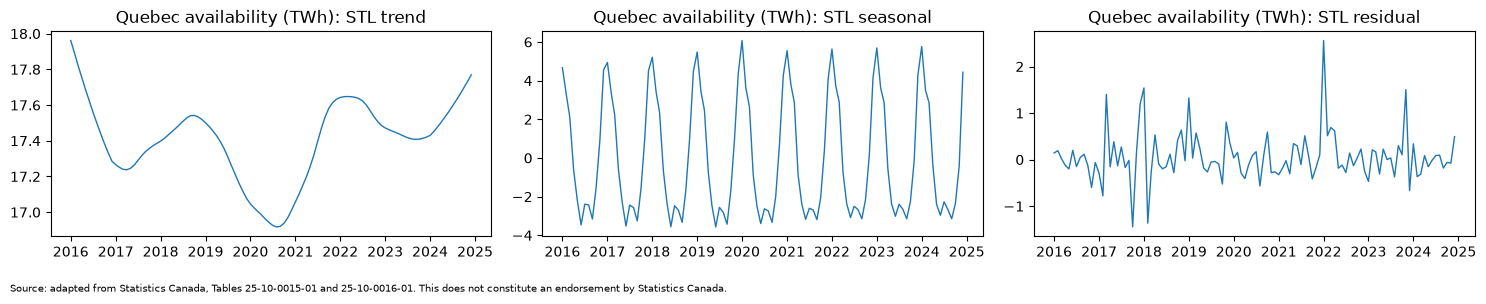

In [12]:
cs = feat["combustion_share"]
clim_dev = T.calendar_climatology(cs)                     # 2016-2024 only: reused unchanged on 2025-26 later
cs_sa = T.deseasonalize(cs, clim_dev)
z_dev = T.stl_z_table(feat, scale_end=c.DISCOVERY_END)
print("deseasonalized combustion share: monthly s.d. by province (percentage points)")
display((cs_sa.groupby(level=0).std() * 100).loc[c.PROVINCES].rename(index=c.ABBR).round(2).to_frame("s.d. (pp)").T)
print(f"STL residual z table: {z_dev.shape[0]:,} geo-months x {z_dev.shape[1]} series; share with |z| > 3 by series:")
display((z_dev.abs() > 3).mean().round(3).to_frame("share |z|>3").T)
from statsmodels.tsa.seasonal import STL
qc = panel.loc["Quebec", "availability"] / 1e6
res = STL(qc.to_numpy(), period=12, robust=True).fit()
fig, ax = plt.subplots(1, 3, figsize=(15, 2.8)); xm = pd.PeriodIndex(qc.index, freq="M").to_timestamp()
for a, (name, v) in zip(ax, [("trend", res.trend), ("seasonal", res.seasonal), ("residual", res.resid)]):
    a.plot(xm, v, lw=1); a.set_title(f"Quebec availability (TWh): STL {name}")
fig.text(0.01, -0.06, ATTRIBUTION, fontsize=7); plt.tight_layout(); plt.savefig(c.FIGURES_DIR / "t_stl_quebec.png", dpi=150, bbox_inches="tight"); plt.show()

**What the transformation shows (description only; the mining comes next):**
- **Three visible kinds of system.** Hydro-dominant (NL, QC, MB, BC, YT: hydro share 0.86–0.97). Combustion-dominant (AB, SK, NS, NU, NT: 0.66–1.00). Mixed nuclear (ON 0.55, NB 0.32). PEI is the odd one: 99% wind, but most of its supply is *imported* (net imports ≈ 61% of availability).
- **Trade separates provinces that the mix doesn't.** NL is a huge net exporter (Churchill Falls power delivered to Quebec: net "imports" −286% of its own availability). Manitoba is a net exporter, mostly to the US. Alberta and Saskatchewan barely trade.
- **Scope of K2:** this is the combustion share of *in-province generation*. For big importers (PEI ≈ 61% of availability; Nova Scotia increasingly) it isn't the same as consumption-side dependence.
- **Seasonality:** the electric-heating provinces (NL, QC, NB, YT) have winter peaks 1.5–1.7× summer. Ontario is flat (0.999): summer air-conditioning balances winter heating.
- **Combustion shares (annual TWh ratios, 2016 → 2024) move in four provinces**, and these are the candidates for K2:
  - **Alberta** falls by about 13 points, from 91.5% to 78.2%;
  - **Nova Scotia** falls by about 8 points, from 81.4% to 73.6%;
  - **Ontario** is 6.7–8.6% in 2017–20, then rises every year to 17.5% in 2024;
  - **New Brunswick** swings widely (31–44%) and jumps to 53% in 2024.

  Both ends of these numbers were visible before the K2 rules were tightened. That's why K2 now needs *three* qualifying provinces besides Ontario, a margin-based persistence test and a burning-vs-denominator attribution.

  Saskatchewan stays at about 80%, and the hydro provinces are near 0. The deseasonalized s.d. per province (NB 12 pp, AB 5, NS 4, ON 4, SK 4) is the noise that PELT's change points have to stand out from.
- **The STL residual z-scores are heavy-tailed**, as expected for monthly energy data: 11–15% of geo-months exceed |z| > 3 (a normal distribution would give 0.3%). That's why K3 uses a fixed flag budget instead of a z threshold.

**K1 feature change (critic round 1):** `seasonal_amplitude` is dropped (r = 0.97 with the winter/summer ratio, so seasonality would count twice). It's no longer in the feature table. NL alone dominates the two trade features; that's reported, not fixed, because it's real (Churchill Falls).

**Outputs:** `data/processed/panel_2016_2024.csv` and `k1_features_2016_2024.csv`; figures `t_profiles_shares_trade.png` and `t_stl_quebec.png`.

> *Critic round 1 reviews KDD steps 1–3 here (`critiques/kdd_steps1-3_round1.md`).*

---
# KDD 4 · Data mining

Four mining tasks, one per goal. Every tuning choice was fixed in `config.py` before this section ran, and every input is development data (≤ 2024-12). Patterns are only *described* here; they're judged against the acceptance rules, the event catalogue and the public record in step 5.

In [13]:
from kddenergy import prereg
m = prereg.verify()      # raises if any rule file changed after the manifest was written
print(f"pre-registration manifest written {m['written_utc']} UTC; {len(m['files'])} rule files unchanged since then")

pre-registration manifest written 2026-11-11T21:14:59+00:00 UTC; 9 rule files unchanged since then


## 4a · K1: clustering geographies (k-means + Ward hierarchical, k by silhouette)

In [14]:
from kddenergy import mining as Mn
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA
sil = Mn.silhouette_table(X_dev)
display(sil.style.format("{:.3f}", subset=["silhouette_kmeans", "silhouette_ward", "ARI_kmeans_vs_ward"]).highlight_max(subset=["silhouette_kmeans"], color="#cde"))
K1_K = Mn.choose_k(sil)
lab_dev = Mn.kmeans_labels(X_dev, K1_K)
lab_ward = Mn.ward_labels(X_dev, K1_K)
print(f"chosen k = {K1_K} (best k-means silhouette); ARI k-means vs Ward at k = {K1_K}: {adjusted_rand_score(lab_dev, lab_ward):.3f}")
members = pd.Series(X_dev.index.map(c.ABBR), index=X_dev.index).groupby(lab_dev).agg(", ".join)
centroids = X_dev.groupby(lab_dev).mean()
display(pd.concat([members.rename("members"), centroids.round(2)], axis=1).rename_axis("cluster"))
print(f"what ARI >= {c.K1_MIN_ARI} means at k = {K1_K}: ARI if exactly one of 13 geographies changes cluster ->", Mn.ari_if_one_moves(lab_dev).round(3).to_dict())

,silhouette_kmeans,silhouette_ward,ARI_kmeans_vs_ward,smallest_cluster
k,,,,
2,0.263,0.267,0.690,6
3,0.278,0.278,1.000,1
4,0.316,0.316,1.000,1
5,0.382,0.382,1.000,1
6,0.353,0.353,1.000,1


chosen k = 5 (best k-means silhouette); ARI k-means vs Ward at k = 5: 1.000


,members,hydro_share,nuclear_share,windsolar_share,combustion_share,net_import_ratio,trade_intensity,us_net_export_ratio,winter_summer_ratio
cluster,,,,,,,,,
0,"NB, ON",0.23,0.44,0.08,0.25,-0.03,0.40,0.13,1.28
1,"QC, MB, BC, YT",0.91,0.00,0.03,0.06,-0.08,0.27,0.09,1.46
2,"NS, SK, AB, NT, NU",0.11,0.00,0.06,0.83,0.03,0.05,-0.00,1.25
3,PE,0.00,0.00,0.99,0.01,0.61,0.98,0.00,1.31
4,NL,0.96,0.00,0.00,0.04,-2.86,2.87,0.13,1.69


what ARI >= 0.7 means at k = 5: ARI if exactly one of 13 geographies changes cluster -> {'min': 0.699, '50%': 0.804, 'max': 0.963}


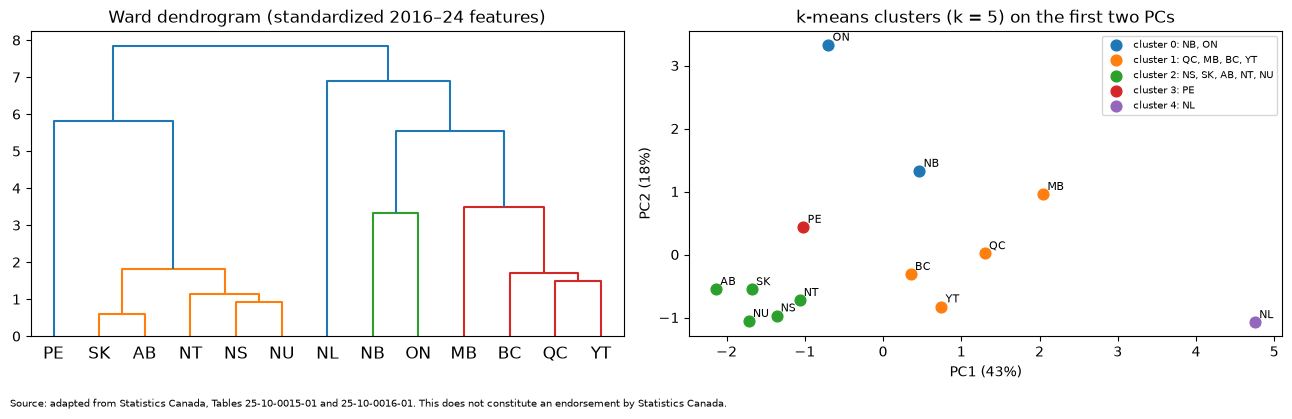

In [15]:
Z = Mn.standardize(X_dev)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dendrogram(linkage(Z, "ward"), labels=list(X_dev.index.map(c.ABBR)), ax=ax[0], color_threshold=None)
ax[0].set_title("Ward dendrogram (standardized 2016–24 features)")
pcs = PCA(2, random_state=c.SEED).fit(Z); P = pcs.transform(Z)
for k in range(K1_K):
    ax[1].scatter(P[lab_dev == k, 0], P[lab_dev == k, 1], s=60, label=f"cluster {k}: {members[k]}")
for (x, y), g in zip(P, X_dev.index):
    ax[1].annotate(c.ABBR[g], (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[1].set(title=f"k-means clusters (k = {K1_K}) on the first two PCs", xlabel=f"PC1 ({pcs.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pcs.explained_variance_ratio_[1]:.0%})")
ax[1].legend(fontsize=7, loc="best")
fig.text(0.01, -0.03, ATTRIBUTION, fontsize=7); plt.tight_layout(); plt.savefig(c.FIGURES_DIR / "m_k1_clusters.png", dpi=150, bbox_inches="tight"); plt.show()

**K1 patterns (development data):**
- **k = 5 wins the silhouette** (0.382; next best k = 6 at 0.353, k = 4 at 0.316).
- **k-means and Ward give identical partitions** at every k ≥ 3 (ARI 1.00), so the result doesn't depend on the algorithm.
- **The five archetypes:**
  1. **Hydro exporters / hydro heating:** QC, MB, BC, YT (hydro share ≈ 0.91);
  2. **Combustion systems:** AB, SK, NS, NT, NU (combustion ≈ 0.83, almost no trade);
  3. **Nuclear-mixed traders:** ON, NB (nuclear ≈ 0.44, trade intensity ≈ 0.40);
  4. **PEI:** a singleton, wind-only generation that covers less than half its own use (net imports 61%);
  5. **NL:** a singleton, the Churchill Falls exporter (net "imports" −286%).
- **The two singletons were predicted by the critic** (outliers in standardized space).
- **What the K1 rule means:** at k = 5, ARI ≥ 0.7 tolerates one geography changing cluster (one-move ARI 0.70–0.96), and stable singletons inflate agreement.

## 4b · K2: change points in each province's combustion share (PELT)

In [16]:
months_dev = sorted(panel.index.get_level_values("month").unique())
k2_rows, k2_fits = [], {}
for g in c.K2_GEOS:
    x = cs_sa.loc[g].to_numpy()
    bk = Mn.pelt(x); ch = Mn.primary_change(x, bk); k2_fits[g] = (x, bk, ch)
    bk_sd = Mn.pelt(x, method=c.K2_SIGMA_SENSITIVITY)
    row = {"province": c.ABBR[g], "change points (all)": ", ".join(months_dev[b] for b in bk) or "none",
           "sensitivity: sigma = s.d.": ", ".join(months_dev[b] for b in bk_sd) or "none"}
    if ch:
        raw_cs = cs.loc[g].to_numpy(); ctrl = Mn.change_controls(panel, g, months_dev, ch)
        frac, attr = Mn.attribution(ctrl)
        row.update({"primary change": months_dev[ch["index"]], "direction": "falling (less combustion)" if ch["shift"] < 0 else "rising (more combustion)",
                    "share before (%)": 100 * raw_cs[ch["pre_start"]:ch["index"]].mean(), "share after (%)": 100 * raw_cs[ch["index"]:ch["post_end"]].mean(),
                    "shift (pp, deseasonalized)": 100 * ch["shift"],
                    "stability: trimmed windows": Mn.trim_stability(x, ch["index"]),
                    "stability: block bootstrap (2nd)": Mn.bootstrap_stability(x, bk, ch["index"]),
                    "survives sigma = s.d.": any(abs(b - ch["index"]) <= c.K2_CHANGEPOINT_TOL_MONTHS for b in bk_sd),
                    "dln(combustion) / dln(share)": frac, "attribution": attr,
                    "last segment mean (pp)": 100 * Mn.segment_means(x, bk)[-1][2], **ctrl})
    k2_rows.append(row)
k2 = pd.DataFrame(k2_rows).set_index("province")
k2["stable"] = k2["stability: trimmed windows"] >= c.K2_MIN_STABILITY
show = ["change points (all)", "primary change", "direction", "share before (%)", "share after (%)", "shift (pp, deseasonalized)",
        "stability: trimmed windows", "stable", "stability: block bootstrap (2nd)", "sensitivity: sigma = s.d.", "survives sigma = s.d.", "attribution"]
display(k2[show].style.format({"share before (%)": "{:.1f}", "share after (%)": "{:.1f}", "shift (pp, deseasonalized)": "{:+.1f}",
                              "stability: trimmed windows": "{:.0%}", "stability: block bootstrap (2nd)": "{:.0%}"}, na_rep="–"))
ctl = [col for col in k2.columns if "GWh" in col] + ["dln(combustion) / dln(share)"]
print("Controls: mean GWh per month in the segment before vs after the primary change point")
display(k2.loc[k2["primary change"].notna(), ctl].round(2))

,change points (all),primary change,direction,share before (%),share after (%),"shift (pp, deseasonalized)",stability: trimmed windows,stable,stability: block bootstrap (2nd),sensitivity: sigma = s.d.,survives sigma = s.d.,attribution
province,,,,,,,,,,,,
NL,"2018-02, 2020-04, 2022-08",2018-02,falling (less combustion),5.3,3.9,-1.4,75%,True,92%,"2018-02, 2022-05",True,burning
PE,"2017-12, 2018-12",2018-12,falling (less combustion),3.3,1.0,-2.2,100%,True,99%,"2017-12, 2018-12",True,burning
NS,2021-12,2021-12,falling (less combustion),79.7,73.7,-6.0,100%,True,89%,2021-12,True,burning
NB,"2017-05, 2019-09, 2020-09, 2024-01",2024-01,rising (more combustion),40.1,56.7,+16.8,50%,False,90%,2024-01,True,denominator
QC,"2018-05, 2023-12",–,–,–,–,–,–,False,–,"2018-05, 2023-12",–,–
ON,"2017-01, 2021-08, 2023-06",2023-06,rising (more combustion),11.4,17.6,+5.6,67%,False,100%,2023-06,True,burning
MB,"2018-07, 2021-05, 2022-05, 2023-05",–,–,–,–,–,–,False,–,2018-01,–,–
SK,"2019-07, 2020-10, 2022-02",2020-10,rising (more combustion),78.5,83.8,+5.2,84%,True,81%,none,False,burning
AB,"2020-05, 2021-09, 2023-01, 2024-01",2023-01,falling (less combustion),86.2,81.0,-5.2,75%,True,100%,2023-01,True,burning


Controls: mean GWh per month in the segment before vs after the primary change point


,combustion pre (GWh/mo),combustion post (GWh/mo),total generation pre (GWh/mo),total generation post (GWh/mo),hydro + nuclear pre (GWh/mo),hydro + nuclear post (GWh/mo),wind + solar pre (GWh/mo),wind + solar post (GWh/mo),net imports pre (GWh/mo),net imports post (GWh/mo),dln(combustion) / dln(share)
province,,,,,,,,,,,
NL,185.14,149.12,3417.80,3687.56,3217.05,3522.38,15.62,16.06,-2463.27,-2691.94,0.74
PE,1.74,0.49,54.68,49.06,0.00,0.00,52.94,48.58,68.07,81.12,1.09
NS,641.05,538.92,804.18,729.96,71.02,72.25,91.48,118.78,51.08,198.31,2.26
NB,449.26,505.74,1111.70,954.19,606.78,366.31,55.66,82.13,9.24,220.29,0.44
ON,1480.19,2391.90,12725.45,13513.14,9880.45,9862.82,1364.81,1258.43,-910.12,-1322.84,1.14
SK,1601.81,1749.82,2035.63,2090.24,362.85,254.44,63.23,77.06,-10.67,-0.45,1.43
AB,5480.30,5212.15,6356.53,6432.90,182.29,163.69,690.01,1054.98,305.16,5.61,0.81
BC,547.76,495.80,5240.44,5954.76,4563.50,5241.53,129.18,217.43,337.00,-599.11,0.44


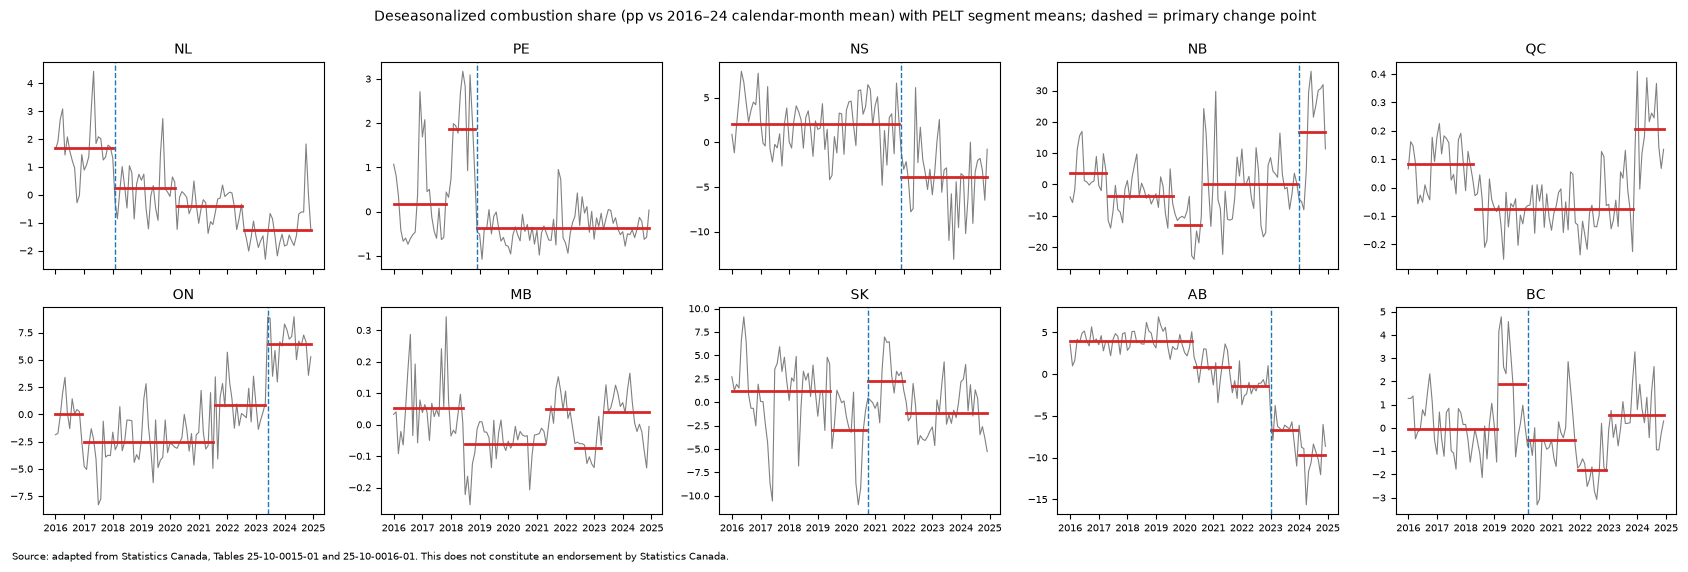

In [17]:
fig, axs = plt.subplots(2, 5, figsize=(17, 5.5), sharex=True)
xm = pd.PeriodIndex(months_dev, freq="M").to_timestamp()
for a, g in zip(axs.flat, c.K2_GEOS):
    x, bk, ch = k2_fits[g]
    a.plot(xm, 100 * x, lw=0.8, color="grey")
    for s0, s1, m in Mn.segment_means(x, bk):
        a.plot(xm[s0:s1], np.full(s1 - s0, 100 * m), color="C3", lw=2)
    if ch: a.axvline(xm[ch["index"]], color="C0", ls="--", lw=1)
    a.set_title(c.ABBR[g], fontsize=10); a.tick_params(labelsize=7)
fig.suptitle("Deseasonalized combustion share (pp vs 2016–24 calendar-month mean) with PELT segment means; dashed = primary change point", fontsize=10)
fig.text(0.01, -0.02, ATTRIBUTION, fontsize=7); plt.tight_layout(); plt.savefig(c.FIGURES_DIR / "m_k2_changepoints.png", dpi=150, bbox_inches="tight"); plt.show()

**K2 patterns (development data, before any persistence check):**
- **8 of 10 provinces have a primary change point of at least 1 pp.** QC and MB don't; their combustion shares are below 1%.
- **Falling (less combustion):**
  - **AB, 2023-01:** −5.2 pp. Combustion −268 GWh/month while wind + solar +365 GWh/month, so it's *burning*.
  - **NS, 2021-12:** −6.0 pp, *burning*; net imports rose.
  - **BC, 2020-03:** −2.4 pp, *denominator*, measured from a 12-month 2019–20 bump; BC's first-to-last segment change is +0.6 pp (no net decline).
  - **NL, 2018-02:** −1.4 pp, *burning*: one step of a four-step staircase (raw share 5.3% → 3.9% at this step; 5.3% → 2.3% from the first to the last segment).
  - **PE, 2018-12:** −2.2 pp, *burning*, but the pre-segment is a 12-month 2018 blip (raw 3.3% → 1.0%); against 2016–17 the fall is only 0.5 pp.
- **Rising:**
  - **ON, 2023-06:** +5.6 pp, *burning* (combustion +912 GWh/month) while hydro + nuclear was flat; trim-stability 67%, just under the 70% bar.
  - **SK, 2020-10:** +5.2 pp, but its last segment had already reversed below the midpoint.
  - **NB, 2024-01:** +16.8 pp, *denominator* (hydro + nuclear −240 GWh/month); trim-stability 50%.
- **Sensitivity:** with the far more conservative σ = s.d., the AB, NS, NB, ON, NL and PE primary change points survive; BC's and SK's disappear. This is reported, not used in the verdict.

## 4c · K3: anomalous months (STL residual z-scores → Isolation Forest)

In [18]:
elig_dev = Mn.eligible_mask(z_dev.index)
zE = z_dev[elig_dev]
iforest = Mn.fit_isolation_forest(zE)
scores_dev = Mn.anomaly_scores(zE, iforest)
N_FLAGS = int(round(c.K3_FLAG_SHARE * len(zE)))
flags_dev = Mn.top_flags(scores_dev["iforest"], N_FLAGS)
flags_z = Mn.top_flags(scores_dev["max_abs_z"], N_FLAGS)
print(f"eligible geo-months: {len(zE):,}; flag budget (2%): {N_FLAGS}; overlap between Isolation Forest and max-|z| flags: {len(flags_dev.intersection(flags_z))}/{N_FLAGS}")
fl = zE.loc[flags_dev].round(1).join(scores_dev["iforest"].round(3))
fl.index = [f"{c.ABBR[g]} {m}" for g, m in fl.index]
display(fl.rename_axis("flag (primary)").T)

eligible geo-months: 1,398; flag budget (2%): 28; overlap between Isolation Forest and max-|z| flags: 20/28


flag (primary),NU 2016-08,NU 2022-12,NU 2020-08,NU 2020-09,NB 2023-08,MB 2021-08,NB 2023-09,NB 2023-07,MB 2021-09,MB 2021-10,...,NL 2021-09,NU 2019-03,BC 2023-07,NL 2023-10,NB 2022-07,NB 2023-11,MB 2021-11,NB 2020-10,MB 2024-05,NU 2021-07
log_availability,-32.200,-28.50,-21.800,-21.700,-1.300,-4.000,0.200,1.000,-2.800,-5.200,...,-8.900,11.800,-0.900,-1.700,-2.200,3.700,-1.400,4.400,-0.300,9.400
log_gen_total,-32.200,-28.50,-21.800,-21.700,17.600,-17.800,14.700,13.900,-15.000,-14.900,...,-0.100,11.800,-12.300,8.400,-10.700,7.000,-14.400,-8.200,-10.800,9.400
net_import_ratio,0.000,0.00,0.000,0.000,-19.000,12.900,-16.900,-13.700,10.600,8.000,...,-9.100,0.000,9.600,-9.000,9.300,-7.700,7.300,7.200,10.400,0.000
iforest,0.776,0.77,0.748,0.747,0.739,0.738,0.732,0.725,0.709,0.704,...,0.665,0.664,0.659,0.658,0.655,0.653,0.649,0.649,0.647,0.644


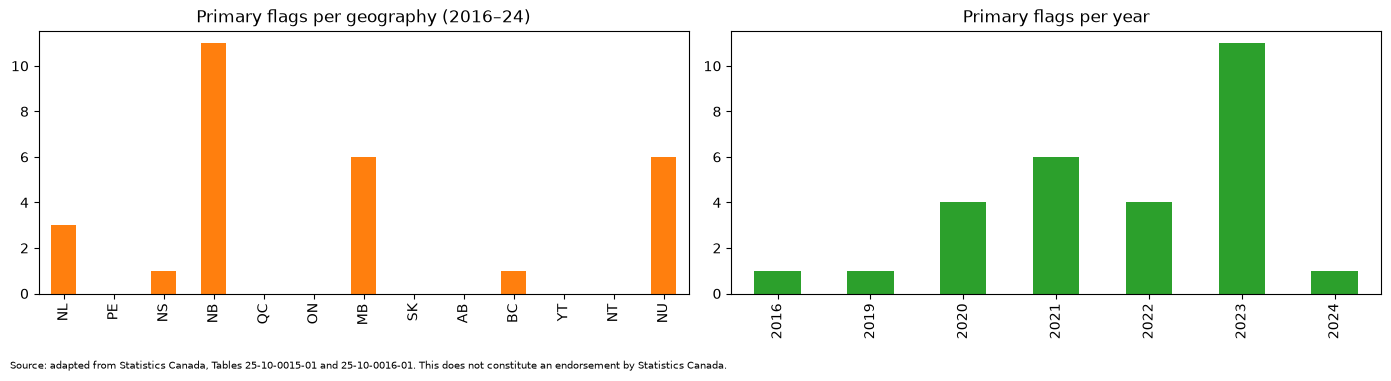

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.6))
per_geo = pd.Series([g for g, _ in flags_dev]).map(c.ABBR).value_counts().reindex([c.ABBR[g] for g in c.GEOS], fill_value=0)
per_geo.plot.bar(ax=axs[0], title="Primary flags per geography (2016–24)", color="C1")
per_year = pd.Series([m[:4] for _, m in flags_dev]).value_counts().sort_index()
per_year.plot.bar(ax=axs[1], title="Primary flags per year", color="C2")
fig.text(0.01, -0.04, ATTRIBUTION, fontsize=7); plt.tight_layout(); plt.savefig(c.FIGURES_DIR / "m_k3_flags.png", dpi=150, bbox_inches="tight"); plt.show()

**K3 patterns (development data):**
- **The 28 flags concentrate in three places:**
  - **Nunavut (6):** a tiny diesel grid with occasional one-month drops of 20–30 robust s.d.;
  - **New Brunswick (11):** large swings between generation and imports;
  - **Manitoba (6):** 2021 and 2023–24, low generation with high net imports.
- **Max-|z| agrees** on 20 of the 28 flags.
- **Whether these match the event catalogue is scored in step 5**, not here.

## 4d · K4: forecasting availability (development origins only)

In [20]:
from kddenergy import forecast as Fc
A_dev = Fc.availability_matrix(load_availability())
dev_rows = Fc.backtest(A_dev, c.DEV_ORIGINS)
file_sn = bt[(bt.geography != "Canada") & bt.usable_prediction].set_index(["forecast_origin", "geography", "month"])["seasonal_naive_mwh"]
mine = pd.Series({(r["origin"], r["geo"], m): v for r in dev_rows for m, v in zip(r["months"], r["snaive"])})
assert len(mine) == len(file_sn) and np.allclose(mine.loc[file_sn.index], file_sn), "seasonal naive differs from the dataset's backtest"
keys = ["snaive", *c.K4_CANDIDATES]
k4_dev = Fc.wape_table(dev_rows, keys)
display(k4_dev.round(2).rename_axis("origin (WAPE %)"))
K4_MODEL = min(c.K4_CANDIDATES, key=lambda k: k4_dev.loc["pooled", k])
ratio, ci = Fc.bootstrap_ratio(dev_rows, K4_MODEL)
wins = np.mean([np.abs(r["y"] - r[K4_MODEL]).sum() < np.abs(r["y"] - r["snaive"]).sum() for r in dev_rows])
print(f"chosen model (lowest pooled development WAPE): {K4_MODEL}; development ratio vs seasonal naive {ratio:.3f} "
      f"(90% bootstrap {ci[0]:.3f}-{ci[1]:.3f}); beats seasonal naive on {wins:.0%} of {len(dev_rows)} geography-origin pairs")

,snaive,avg3_growth,ets_damped_log,combo_avg3_ets
origin (WAPE %),,,,
2018-12,3.25,3.29,3.31,3.17
2019-12,3.90,3.93,4.01,3.94
2020-12,4.24,3.78,3.58,3.55
2021-12,4.56,4.19,4.35,4.23
2022-12,4.52,3.65,3.30,3.39
2023-12,4.03,3.46,3.34,3.30
pooled,4.08,3.71,3.65,3.59


chosen model (lowest pooled development WAPE): combo_avg3_ets; development ratio vs seasonal naive 0.880 (90% bootstrap 0.827-0.931); beats seasonal naive on 78% of 78 geography-origin pairs


**K4 model choice (development origins only):**
- **The equal-weight combination** of the growth-adjusted 3-year seasonal mean and a damped Holt-Winters on log availability has the lowest pooled WAPE: 3.59% vs seasonal naive 4.08%, ratio 0.880 (90% interval 0.827–0.931).
- It's better on 78% of 78 geography-origin pairs, but **not at every origin** (2019-12: 3.94% vs 3.90%).
- It's the only model scored on the sealed origins.

---
# KDD 5 · Interpretation / evaluation

**The seal is lifted here, once.** Code cells below are the only ones that read sealed *values* (`allow_sealed=True`). The front pass (F.2) also called a loader with `allow_sealed=True`, but only for structural checks, and it printed just a *count* of sealed identity exceptions. The order is fixed:
1. score every pre-registered acceptance rule (K1–K4) exactly as written in `config.py`;
2. only then interpret the patterns against the public record and rank them by interestingness.

Nothing mined in step 4 is re-tuned after this point.

In [21]:
prereg.verify()                                         # rules unchanged since the manifest
raw_all = build_panel(allow_sealed=True)
panel_all, _ = clean(raw_all)
feat_all = T.add_features(panel_all)
m_all = panel_all.index.get_level_values("month")
print("unsealed panel:", m_all.min(), "->", m_all.max(), f"({panel_all.shape[0]:,} geo-months); missing cells: {int(panel_all.isna().sum().sum())}")
print(integration_checks(panel_all[m_all >= c.CONFIRM_START]).to_dict())

unsealed panel: 2016-01 -> 2026-08 (1,664 geo-months); missing cells: 0
{'geo-months': 260.0, 'max |generation table - flows table|': 0.0, 'geo-months with |availability identity residual| > 1': 0.0, 'max |availability identity residual|': 0.0, 'max |types sum - total generation|': 2389.0, 'max |receipt parts - total receipts|': 0.0, 'max |delivery parts - total deliveries|': 0.0}


## 5a · K1: do the archetypes persist in 2025–26?

In [22]:
X_conf = T.cluster_features(panel_all, c.CONFIRM_START, c.DATA_END)
lab_conf = Mn.kmeans_labels(X_conf, K1_K)                 # PRIMARY: same pipeline re-run on the confirmation window
ari_primary = adjusted_rand_score(lab_dev, lab_conf)
from sklearn.preprocessing import StandardScaler
sc_dev = StandardScaler().fit(X_dev.to_numpy())             # SECONDARY: development scaler + nearest development centroid
cent = np.array([sc_dev.transform(X_dev.to_numpy())[lab_dev == k].mean(axis=0) for k in range(K1_K)])
lab_nn = np.argmin(((sc_dev.transform(X_conf.to_numpy())[:, None, :] - cent[None]) ** 2).sum(axis=2), axis=1)
ari_secondary = adjusted_rand_score(lab_dev, lab_nn)
co = pd.DataFrame({"2016–24 cluster": lab_dev, "2025–26 re-clustered": Mn.relabel_like(lab_dev, lab_conf),
                   "2025–26 nearest dev centroid": lab_nn}, index=X_dev.index.map(c.ABBR))
co["same (primary)"] = co["2016–24 cluster"] == co["2025–26 re-clustered"]
display(co.T)
K1_MET = ari_primary >= c.K1_MIN_ARI
print(f"K1 primary ARI = {ari_primary:.3f} (rule >= {c.K1_MIN_ARI}) -> {'MET' if K1_MET else 'NOT MET'}; secondary (dev scaler, nearest centroid) ARI = {ari_secondary:.3f}")
display(pd.concat({"2016–24": X_dev, "2025–26": X_conf}, axis=1).swaplevel(axis=1).sort_index(axis=1)[["combustion_share", "windsolar_share", "net_import_ratio"]].rename(index=c.ABBR).round(3))

geography,NL,PE,NS,NB,QC,ON,MB,SK,AB,BC,YT,NT,NU
2016–24 cluster,4,3,2,0,1,0,1,2,2,1,1,2,2
2025–26 re-clustered,4,3,2,0,1,0,1,2,2,1,1,2,2
2025–26 nearest dev centroid,4,3,2,0,1,0,1,2,2,1,1,2,2
same (primary),True,True,True,True,True,True,True,True,True,True,True,True,True


K1 primary ARI = 1.000 (rule >= 0.7) -> MET; secondary (dev scaler, nearest centroid) ARI = 1.000


combustion_share         windsolar_share         net_import_ratio  \
                   2016–24 2025–26         2016–24 2025–26          2016–24   
geography                                                                     
NL                   0.037   0.033           0.004   0.005           -2.861   
PE                   0.014   0.010           0.986   0.990            0.607   
NS                   0.778   0.750           0.129   0.185            0.115   
NB                   0.397   0.516           0.059   0.092            0.027   
QC                   0.010   0.010           0.051   0.062            0.009   
ON                   0.109   0.224           0.093   0.097           -0.092   
MB                   0.003   0.003           0.027   0.032           -0.306   
SK                   0.814   0.763           0.047   0.105            0.012   
AB                   0.878   0.748           0.094   0.223            0.022   
BC                   0.087   0.078           0.026   0.026           -0.008   
YT                   0.135   0.309           0.002   0.023            0.000   
NT                   0.658   0.652           0.025   0.035            0.000   
NU                   1.000   0.999           0.000   0.001            0.000   

                   
          2025–26  
geography          
NL         -2.072  
PE          0.619  
NS          0.198  
NB          0.118  
QC          0.130  
ON         -0.125  
MB         -0.071  
SK          0.005  
AB         -0.020  
BC          0.015  
YT          0.000  
NT          0.000  
NU          0.000

In [23]:
adj_k = {k: adjusted_rand_score(Mn.kmeans_labels(X_dev, k), Mn.kmeans_labels(X_conf, k)) for k in c.K1_K_RANGE}
print("POST-HOC sensitivity (not the rule): confirmation ARI at other k ->", {k: round(v, 2) for k, v in adj_k.items()})
drift = (X_conf - X_dev).abs().max().sort_values(ascending=False)
print("largest within-geography feature changes, 2016-24 -> 2025-26:", drift.round(2).head(4).to_dict())

POST-HOC sensitivity (not the rule): confirmation ARI at other k -> {2: 0.03, 3: 0.27, 4: 0.6, 5: 1.0, 6: 0.84}
largest within-geography feature changes, 2016-24 -> 2025-26: {'trade_intensity': 0.79, 'net_import_ratio': 0.79, 'us_net_export_ratio': 0.26, 'hydro_share': 0.2}


## 5b · K2: do the change points persist, and are they structural?

In [24]:
cs_all = feat_all["combustion_share"]
cs_all_sa = T.deseasonalize(cs_all, clim_dev)               # the 2016-24 climatology, unchanged
conf_mean = cs_all_sa[cs_all_sa.index.get_level_values("month") >= c.CONFIRM_START].groupby(level=0).mean()
rows = []
for g in c.K2_GEOS:
    x, bk, ch = k2_fits[g]
    r = {"province": c.ABBR[g]}
    if ch is None:
        r.update({"primary change": "none", "verdict": "no change >= 1 pp"}); rows.append(r); continue
    last = Mn.segment_means(x, bk)[-1][2]
    pers = Mn.persistence(conf_mean[g], ch["pre_mean"], ch["post_mean"], last)
    stable = k2.loc[c.ABBR[g], "stable"]
    r.update({"primary change": months_dev[ch["index"]], "direction": k2.loc[c.ABBR[g], "direction"],
              "pre (pp)": 100 * ch["pre_mean"], "post (pp)": 100 * ch["post_mean"], "last dev segment (pp)": 100 * last,
              "2025–26 mean (pp)": 100 * conf_mean[g], "stable": stable, "persistent": pers,
              "attribution": k2.loc[c.ABBR[g], "attribution"],
              "verdict": "qualifies" if (stable and pers) else ("not stable" if not stable else "did not persist")})
    rows.append(r)
k2_eval = pd.DataFrame(rows).set_index("province")
display(k2_eval.style.format({col: "{:+.1f}" for col in ["pre (pp)", "post (pp)", "last dev segment (pp)", "2025–26 mean (pp)"]}, na_rep="–"))
qual = [p for p in k2_eval.index if p != "ON" and k2_eval.loc[p, "verdict"] == "qualifies"]
K2_MET = len(qual) >= 3
print(f"qualifying provinces other than Ontario: {qual} -> K2 {'MET' if K2_MET else 'NOT MET'} (rule: >= 3)")
print("Ontario (reported separately, confirmation partly spent):", k2_eval.loc["ON", "verdict"])

,primary change,direction,pre (pp),post (pp),last dev segment (pp),2025–26 mean (pp),stable,persistent,attribution,verdict
province,,,,,,,,,,
NL,2018-02,falling (less combustion),+1.7,+0.2,-1.3,-0.5,True,True,burning,qualifies
PE,2018-12,falling (less combustion),+1.9,-0.4,-0.4,-0.4,True,True,burning,qualifies
NS,2021-12,falling (less combustion),+2.1,-3.9,-3.9,-4.0,True,True,burning,qualifies
NB,2024-01,rising (more combustion),+0.1,+16.9,+16.9,+13.1,False,True,denominator,not stable
QC,none,–,–,–,–,–,–,–,–,no change >= 1 pp
ON,2023-06,rising (more combustion),+0.8,+6.5,+6.5,+10.9,False,True,burning,not stable
MB,none,–,–,–,–,–,–,–,–,no change >= 1 pp
SK,2020-10,rising (more combustion),-3.0,+2.2,-1.2,-5.3,True,False,burning,did not persist
AB,2023-01,falling (less combustion),-1.5,-6.7,-9.7,-13.3,True,True,burning,qualifies


qualifying provinces other than Ontario: ['NL', 'PE', 'NS', 'AB', 'BC'] -> K2 MET (rule: >= 3)
Ontario (reported separately, confirmation partly spent): not stable


In [25]:
# POST-HOC sensitivity (critic round 2), disclosed: it does NOT change the pre-registered verdict above
sens = []
for g in c.K2_GEOS:
    x, bk, ch = k2_fits[g]
    if ch is None:
        continue
    segs = Mn.segment_means(x, bk)
    f2l = segs[-1][2] - segs[0][2]
    a = np.sign(f2l) == np.sign(ch["shift"]) and abs(f2l) * 100 >= c.K2_MIN_SHIFT_PP
    b = min(ch["index"] - ch["pre_start"], ch["post_end"] - ch["index"]) >= 18
    burn = k2.loc[c.ABBR[g], "attribution"] == "burning"
    sens.append({"province": c.ABBR[g], "rule verdict": k2_eval.loc[c.ABBR[g], "verdict"], "first->last segment (pp)": 100 * f2l,
                 "(a) net change >= 1 pp, same sign": a, "pre/post segment months": f"{ch['index'] - ch['pre_start']}/{ch['post_end'] - ch['index']}",
                 "(b) both >= 18 months": b, "(c) attribution = burning": burn})
sens = pd.DataFrame(sens).set_index("province")
display(sens.style.format({"first->last segment (pp)": "{:+.2f}"}))
sub = [p for p in sens.index if p != "ON" and sens.loc[p, "rule verdict"] == "qualifies" and sens.loc[p, "(a) net change >= 1 pp, same sign"] and sens.loc[p, "(c) attribution = burning"]]
print(f"qualifying under (a) + (c): {sub} -> {len(sub)} of the >= 3 needed; adding (b) would also remove AB (its ramp is cut into 16- and 12-month segments)")

,rule verdict,first->last segment (pp),"(a) net change >= 1 pp, same sign",pre/post segment months,(b) both >= 18 months,(c) attribution = burning
province,,,,,,
NL,qualifies,-2.96,True,25/26,True,True
PE,qualifies,-0.54,False,12/73,False,True
NS,qualifies,-6.00,True,71/37,True,True
NB,not stable,+13.30,True,40/12,False,False
ON,not stable,+6.45,True,22/19,True,True
SK,did not persist,-2.36,False,15/16,False,True
AB,qualifies,-13.65,True,16/12,False,True
BC,qualifies,+0.61,False,12/21,False,False


qualifying under (a) + (c): ['NL', 'NS', 'AB'] -> 3 of the >= 3 needed; adding (b) would also remove AB (its ramp is cut into 16- and 12-month segments)


In [26]:
yr_all = panel_all[["combustion", "gen_total", "hydro", "nuclear", "wind", "solar"]].groupby(panel_all.index.get_level_values(1).str[:4]).sum()
nat = pd.DataFrame({"combustion share (%)": 100 * yr_all["combustion"] / yr_all["gen_total"],
                    "hydro (TWh)": yr_all["hydro"] / 1e6, "nuclear (TWh)": yr_all["nuclear"] / 1e6,
                    "wind + solar (TWh)": (yr_all["wind"] + yr_all["solar"]) / 1e6, "total (TWh)": yr_all["gen_total"] / 1e6})
nat.index = [f"{y} (Jan–Aug)" if y == c.DATA_END[:4] else y for y in nat.index]
display(nat.round(1).T)

,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026 (Jan–Aug)
combustion share (%),21.2,20.0,20.3,20.6,19.1,19.8,19.2,20.6,22.1,22.9,22.1
hydro (TWh),381.4,390.8,381.6,377.6,382.6,377.0,392.4,359.3,341.8,343.4,246.1
nuclear (TWh),95.7,95.7,95.0,95.5,92.7,87.4,82.3,84.6,81.7,81.6,54.7
wind + solar (TWh),32.3,33.0,34.1,35.3,38.8,38.9,42.3,44.3,51.1,56.5,37.8
total (TWh),646.3,649.4,641.5,640.4,635.6,627.7,640.1,615.3,609.5,625.2,434.9


In [27]:
d = yr_all.loc["2025"] - yr_all.loc["2016"]
by_geo = (panel_all["combustion"].groupby([panel_all.index.get_level_values(0), panel_all.index.get_level_values(1).str[:4]]).sum().unstack(1))
dc = ((by_geo["2025"] - by_geo["2016"]) / 1e6).rename(index=c.ABBR).sort_values()
held = 100 * yr_all.loc["2025", "combustion"] / yr_all.loc["2016", "gen_total"]
print(f"combustion 2016 -> 2025: {yr_all.loc['2016', 'combustion'] / 1e6:.1f} -> {yr_all.loc['2025', 'combustion'] / 1e6:.1f} TWh; by geography (TWh):", dc.round(1).to_dict())
print(f"share 2025 = {nat.loc['2025', 'combustion share (%)']:.2f}%; holding total generation at its 2016 level it would be {held:.2f}% "
      f"-> the shrinking denominator explains {(nat.loc['2025', 'combustion share (%)'] - held) / (nat.loc['2025', 'combustion share (%)'] - nat.loc['2016', 'combustion share (%)']):.0%} of the rise")

combustion 2016 -> 2025: 136.7 -> 143.4 TWh; by geography (TWh): {'AB': -6.7, 'NS': -1.3, 'BC': -1.1, 'SK': -1.0, 'NL': -0.9, 'NB': -0.7, 'QC': -0.4, 'NT': -0.1, 'MB': -0.1, 'PE': -0.0, 'YT': 0.2, 'NU': 0.2, 'ON': 18.6}
share 2025 = 22.94%; holding total generation at its 2016 level it would be 22.19% -> the shrinking denominator explains 42% of the rise


## 5c · K3: do the flags match public-record events?

In [28]:
score = Mn.score_flags(flags_dev, covered, cat_dev, eligible)
p_perm, null = Mn.permutation_p(flags_dev, cat_dev, eligible)
K3_MET = score["event_level_precision"] >= c.K3_MIN_CATALOGUE_PRECISION and p_perm <= c.K3_MAX_P
print(f"K3 (2016-24): event-level precision {score['event_level_precision']:.2f} ({score['event_level_credit']}/{score['flags']}), "
      f"permutation p = {p_perm:.3f} (null mean {null.mean():.2f}, 95th pct {np.percentile(null, 95):.2f}) -> {'MET' if K3_MET else 'NOT MET'}")
print(f"secondary: flag-level precision {score['precision']:.2f}, base rate {score['base_rate']:.3f}, lift {score['lift']:.2f}; "
      f"events hit {score['events_hit']}/{score['events']} (recall {score['recall']:.2f})")
def match(g, m):
    hits = [r.event_id + " " + r.event_type for r in cat_dev.itertuples() if r.geography == g and
            pd.Period(r.start_month, "M") - 1 <= pd.Period(m, "M") <= pd.Period(r.end_month, "M") + 1]
    return ", ".join(hits) or "–"
fl_tab = pd.DataFrame([{"flag": f"{c.ABBR[g]} {m}", "catalogue match": match(g, m), "edge year": m[:4] in ("2016", "2024"),
                        **zE.loc[(g, m)].round(1).to_dict()} for g, m in flags_dev])
display(fl_tab)
alt = Mn.score_flags(flags_z, covered, cat_dev, eligible)
p_alt = Mn.permutation_p(flags_z, cat_dev, eligible)[0]
print(f"comparison detector (max |z|, same budget; not the pre-registered primary): event-level precision {alt['event_level_precision']:.2f} "
      f"(p = {p_alt:.3f}), flag-level {alt['precision']:.2f}")
nb_ = panel.loc["New Brunswick", ["nuclear", "combustion", "gen_total"]] / 1e3
print("NB GWh/month, summers (Jun-Sep):"); display(pd.concat({y: nb_.loc[f"{y}-06":f"{y}-09"].mean() for y in ["2019", "2021", "2022", "2023", "2024"]}, axis=1).round(0))
prov_flags = [f for f in flags_dev if f[0] in c.PROVINCES]
sp = Mn.score_flags(prov_flags, covered, cat_dev, eligible)
print(f"descriptive only (not the rule): the {len(prov_flags)} flags in provinces have event-level precision {sp['event_level_precision']:.2f}")

K3 (2016-24): event-level precision 0.11 (3/28), permutation p = 0.246 (null mean 0.07, 95th pct 0.14) -> NOT MET
secondary: flag-level precision 0.25, base rate 0.132, lift 1.89; events hit 3/40 (recall 0.07)


,flag,catalogue match,edge year,log_availability,log_gen_total,net_import_ratio
0,NU 2016-08,–,True,-32.2,-32.2,0.0
1,NU 2022-12,–,False,-28.5,-28.5,0.0
2,NU 2020-08,–,False,-21.8,-21.8,0.0
3,NU 2020-09,–,False,-21.7,-21.7,0.0
4,NB 2023-08,–,False,-1.3,17.6,-19.0
5,MB 2021-08,E18 drought,False,-4.0,-17.8,12.9
6,NB 2023-09,–,False,0.2,14.7,-16.9
7,NB 2023-07,–,False,1.0,13.9,-13.7
8,MB 2021-09,E18 drought,False,-2.8,-15.0,10.6
9,MB 2021-10,E18 drought,False,-5.2,-14.9,8.0


comparison detector (max |z|, same budget; not the pre-registered primary): event-level precision 0.21 (p = 0.012), flag-level 0.39
NB GWh/month, summers (Jun-Sep):


,2019,2021,2022,2023,2024
nuclear,451.0,474.0,212.0,480.0,0.0
combustion,308.0,265.0,279.0,490.0,438.0
gen_total,963.0,920.0,744.0,1360.0,671.0


descriptive only (not the rule): the 22 flags in provinces have event-level precision 0.14


In [29]:
conf_months = [m for m in sorted(set(m_all)) if m >= c.CONFIRM_START]
z_conf = T.stl_z_onesided(feat_all, conf_months, scale_end=c.DISCOVERY_END)
z_conf = z_conf[Mn.eligible_mask(z_conf.index)]
s_conf = Mn.anomaly_scores(z_conf, iforest)                 # the frozen Isolation Forest
thr = scores_dev.loc[flags_dev, "iforest"].min()            # the frozen threshold (score of the last discovery flag)
flags_conf = s_conf.index[s_conf["iforest"] >= thr]
cat_conf = load_event_catalogue("confirmation")
cov_conf = catalogue_months(cat_conf, window=c.K3_MATCH_MONTHS)
sc_conf = Mn.score_flags(flags_conf, cov_conf, cat_conf, list(z_conf.index)) if len(flags_conf) else {}
print(f"confirmation 2025-01..{c.DATA_END}: {len(flags_conf)} flags above the frozen threshold {thr:.3f} out of {len(z_conf)} eligible geo-months")
display(pd.DataFrame([{"flag": f"{c.ABBR[g]} {m}", **z_conf.loc[(g, m)].round(1).to_dict(), "iforest": round(s_conf.loc[(g, m), 'iforest'], 3),
                       "confirmation-catalogue match": any((g, m) == x for x in cov_conf)} for g, m in flags_conf]))
if sc_conf:
    print(f"confirmation (secondary): event-level precision {sc_conf['event_level_precision']:.2f}; events hit {sc_conf['events_hit']}/{sc_conf['events']}")
print("one-sided (endpoint) STL is conservative: share |z| > 3 in 2025-26 =", (z_conf.abs() > 3).mean().round(3).to_dict(), "vs development", (zE.abs() > 3).mean().round(3).to_dict())

confirmation 2025-01..2026-08: 4 flags above the frozen threshold 0.644 out of 240 eligible geo-months


,flag,log_availability,log_gen_total,net_import_ratio,iforest,confirmation-catalogue match
0,BC 2026-04,0.3,12.5,-7.7,0.663,False
1,MB 2025-07,-0.1,-20.9,11.2,0.710,True
2,MB 2026-06,1.0,12.4,-7.7,0.667,False
3,YT 2025-07,11.3,11.3,0.0,0.658,False


confirmation (secondary): event-level precision 0.25; events hit 1/4
one-sided (endpoint) STL is conservative: share |z| > 3 in 2025-26 = {'log_availability': 0.017, 'log_gen_total': 0.046, 'net_import_ratio': 0.025} vs development {'log_availability': 0.105, 'log_gen_total': 0.151, 'net_import_ratio': 0.107}


## 5d · K4: the sealed forecast origins (scored once)

In [30]:
A_all = Fc.availability_matrix(load_availability(allow_sealed=True))
sealed_rows = Fc.backtest(A_all, c.SEALED_ORIGINS, methods={"snaive": Fc.seasonal_naive, "avg3_growth": Fc.avg3_growth, "ets_damped_log": Fc.ets_damped_log})
bt_all = load_backtest(allow_sealed=True)
file_sealed = bt_all[(bt_all.geography != "Canada") & bt_all.usable_prediction & bt_all.forecast_origin.isin(c.SEALED_ORIGINS)].set_index(["forecast_origin", "geography", "month"])["seasonal_naive_mwh"]
mine_s = pd.Series({(r["origin"], r["geo"], m): v for r in sealed_rows for m, v in zip(r["months"], r["snaive"])})
common = mine_s.index.intersection(file_sealed.index)
assert np.allclose(mine_s.loc[common], file_sealed.loc[common]); print(f"seasonal naive matches the dataset's file on {len(common)} sealed forecasts (mine: {len(mine_s)})")
k4_sealed = Fc.wape_table(sealed_rows, ["snaive", K4_MODEL])
k4_sealed["ratio"] = k4_sealed[K4_MODEL] / k4_sealed["snaive"]
display(k4_sealed.round(3).rename_axis("sealed origin (WAPE %)"))
ratio_s, ci_s = Fc.bootstrap_ratio(sealed_rows, K4_MODEL)
both = all(k4_sealed.loc[o, K4_MODEL] < k4_sealed.loc[o, "snaive"] for o in c.SEALED_ORIGINS)
K4_MET = ratio_s <= c.K4_MAX_WAPE_RATIO and both
print(f"K4: pooled sealed ratio {ratio_s:.3f} (90% bootstrap {ci_s[0]:.3f}-{ci_s[1]:.3f}; rule <= {c.K4_MAX_WAPE_RATIO}), better at both origins: {both} -> {'MET' if K4_MET else 'NOT MET'}")
per_geo = pd.DataFrame([{"origin": r["origin"], "geo": c.ABBR[r["geo"]], "snaive": 100 * np.abs(r["y"] - r["snaive"]).sum() / r["y"].sum(),
                         K4_MODEL: 100 * np.abs(r["y"] - r[K4_MODEL]).sum() / r["y"].sum()} for r in sealed_rows])
display(per_geo.pivot(index="geo", columns="origin").round(1))
r25 = [r for r in sealed_rows if r["origin"] == "2025-12"]
err = pd.DataFrame({k: {c.ABBR[r["geo"]]: np.abs(r["y"] - r[k]).sum() for r in r25} for k in ["snaive", K4_MODEL]})
print("2025-12 origin: share of pooled absolute error by geography (%)"); display((100 * err / err.sum()).round(0).T)

seasonal naive matches the dataset's file on 156 sealed forecasts (mine: 260)


,snaive,combo_avg3_ets,ratio
sealed origin (WAPE %),,,
2024-12,4.306,4.171,0.969
2025-12,2.322,2.658,1.145
pooled,3.510,3.564,1.015


K4: pooled sealed ratio 1.015 (90% bootstrap 0.924-1.154; rule <= 0.9), better at both origins: False -> NOT MET


snaive         combo_avg3_ets        
origin 2024-12 2025-12        2024-12 2025-12
geo                                          
AB         6.6     2.9            5.1     2.7
BC         2.4     2.7            3.9     2.8
MB         5.5     6.4            4.7     5.5
NB         4.6     4.0            5.2     4.5
NL         8.2     6.6            7.6     6.1
NS         3.8     2.8            4.2     3.7
NT         4.4    22.0            3.6    21.2
NU        37.8    17.3           22.4    12.8
ON         3.1     1.4            3.5     1.9
PE         5.1     5.8            5.0     6.1
QC         4.6     1.6            4.2     2.4
SK         3.1     2.3            2.0     1.9
YT        13.2    16.2            8.6     9.5

2025-12 origin: share of pooled absolute error by geography (%)


,NL,PE,NS,NB,QC,ON,MB,SK,AB,BC,YT,NT,NU
snaive,6.0,1.0,2.0,4.0,25.0,15.0,12.0,4.0,17.0,13.0,1.0,1.0,1.0
combo_avg3_ets,4.0,1.0,3.0,4.0,32.0,18.0,9.0,3.0,13.0,12.0,0.0,1.0,0.0


## 5e · Acceptance summary (pre-registered rules, applied as written)

In [31]:
acc = pd.DataFrame([
    {"goal": "K1 archetypes", "rule": f"ARI(2016-24 vs 2025-26 clusters) >= {c.K1_MIN_ARI}", "result": f"ARI = {ari_primary:.2f} (secondary {ari_secondary:.2f})", "verdict": "MET" if K1_MET else "NOT MET"},
    {"goal": "K2 structural change", "rule": ">= 3 non-Ontario provinces with a stable AND persistent change point", "result": f"{len(qual)} qualify: {', '.join(qual) or 'none'} (post hoc, net + burning: {', '.join(sub)})", "verdict": ("MET as written" if K2_MET else "NOT MET")},
    {"goal": "K3 anomalies", "rule": f"event-level precision >= {c.K3_MIN_CATALOGUE_PRECISION} AND permutation p <= {c.K3_MAX_P}", "result": f"{score['event_level_precision']:.2f}, p = {p_perm:.3f}", "verdict": "MET" if K3_MET else "NOT MET"},
    {"goal": "K4 prediction", "rule": f"sealed pooled WAPE ratio <= {c.K4_MAX_WAPE_RATIO} AND better at both origins", "result": f"ratio {ratio_s:.3f} [{ci_s[0]:.2f}, {ci_s[1]:.2f}]; both: {both}", "verdict": "MET" if K4_MET else "NOT MET"},
])
display(acc.set_index("goal"))
c.PROCESSED.mkdir(exist_ok=True); acc.to_csv(c.PROCESSED / "acceptance.csv", index=False)

,rule,result,verdict
goal,,,
K1 archetypes,ARI(2016-24 vs 2025-26 clusters) >= 0.7,ARI = 1.00 (secondary 1.00),MET
K2 structural change,>= 3 non-Ontario provinces with a stable AND p...,"5 qualify: NL, PE, NS, AB, BC (post hoc, net +...",MET as written
K3 anomalies,event-level precision >= 0.5 AND permutation p...,"0.11, p = 0.246",NOT MET
K4 prediction,sealed pooled WAPE ratio <= 0.9 AND better at ...,"ratio 1.015 [0.92, 1.15]; both: False",NOT MET


## 5f · Interpretation: what the patterns mean, checked against the public record

**Verdicts first** (rules applied exactly as pre-registered):

| Goal | Verdict | One-sentence reading |
|---|---|---|
| K1 | **MET** (ARI 1.00) | The k = 5 partition persists in 2025–26. *Post hoc:* ARI is 0.27 / 0.61 / 0.84 at k = 3 / 4 / 6, and within-archetype drift is large (e.g. ON combustion 0.11 → 0.22, YT 0.14 → 0.31), so the persistence is specific to k = 5 |
| K2 | **MET as written** (5 of ≥ 3) | The rule fired for NL, PE, NS, AB and BC. **In substance it holds for two large, burning-driven declines (AB, NS) plus a small NL decline.** BC (+0.6 pp first-to-last) and PE (−0.5 pp vs 2016–17) qualified only because a 12-month blip ended. Under the disclosed post-hoc sensitivity (a: net first-to-last change ≥ 1 pp; c: burning-driven), 3 remain (NL, NS, AB), so the verdict hangs on NL's ≈ 1.4 pp step |
| K3 | **NOT MET** | Event-level precision 0.11 (3/28), permutation p = 0.25: the detector finds no more catalogue events than chance placement would |
| K4 | **NOT MET** | Sealed pooled WAPE ratio 1.015: a little better than seasonal naive at the 2024-12 origin (0.969), worse over Jan–Aug 2026 (1.145) |

**Is Canada's grid becoming less combustion-dependent? Not nationally, and that's the main finding.**
- The 13-geography combustion share was 21.2% in 2016, 19.1% at its 2020 low, 22.1% in 2024 and **22.9% in 2025**.
- Underneath, the provinces split:
  - **Alberta and Nova Scotia** are measurably less combustion-dependent. Alberta's share kept falling in the confirmation period (76.0% in 2025, 72.4% in Jan–Aug 2026).
  - **Ontario** went the other way: 6.7–8.7% in 2017–20, then 17.5% in 2024, 21.0% in 2025 and 23.1% in Jan–Aug 2026. Since 2019, nuclear output is down 12 TWh a year (90.5 → 78.3 TWh in 2025, refurbishments) while combustion is up about 22 TWh. Roughly half is nuclear substitution; the rest is demand growth and higher exports. Across the 2023-06 change itself, combustion rose 912 GWh/month, availability about 375 and net exports about 413, so that step is demand plus exports, not refurbishment.
  - **Hydro-drought years** (QC, BC, MB 2023–24) cut the denominator.
- **Decomposition (descriptive, not a tested rule; the national 2025 figure was already seen in the front pass):** combustion rose 136.7 → 143.4 TWh from 2016 to 2025 (ON +18.6, AB −6.7, others about −5). Holding total generation at its 2016 level, the 2025 share would be 22.2%, so the shrinking denominator (2023–24 hydro drought) explains about 40% of the 21.2 → 22.9 point rise. The national number is a tug-of-war between Ontario's burning and Alberta's decline, plus drought. That's knowledge a national headline hides.

**Validation against the public record** (consistency checks from public reporting; the analyst didn't re-verify primary sources line by line):

| Finding | Public record it's consistent with | Confidence |
|---|---|---|
| AB combustion share falls from 2023 | Alberta's large wind and solar build-out in 2023–24, and the end of coal-fired generation in 2024 (coal → gas leaves the combustion share unchanged, so the fall comes from renewables) | High: large, stable, persistent, burning-driven |
| NS share falls from 2021-12, with net imports rising | Hydro imports from Muskrat Falls over the Maritime Link ramping up in the early 2020s; coal-unit reductions | Medium–high |
| ON share rises from 2023 (not stable by the rule, and confirmation partly spent) | Since 2019: nuclear refurbishments (Darlington, Bruce) and Pickering's wind-down cut nuclear output 12 TWh/yr, about half of the combustion rise; the 2023 step itself is demand plus exports | Medium (descriptive) |
| BC "fall" 2020-03 | The end of a 12-month 2019–20 bump; no net decline (+0.6 pp first-to-last) | Not a finding |
| NL small fall; PE "fall" | NL: a staircase 5.3% → 2.3% (less thermal use); PE: the end of a 2018 blip (−0.5 pp vs 2016–17) | NL low–medium; PE not a finding |
| K3 flags in NB | **Only 4 of 11** coincide with a nuclear outage (2020-09/10, 2022-06/07; nuclear 0 in May–June 2022). The **2023 flags are combustion and exports**: NB combustion 386–577 GWh/month and total generation 1,272–1,442 (vs ≈ 900–1,000) with nuclear normal, consistent with exports to a drought-hit Quebec (E32), which same-geography matching can't credit. The longest outage in the record (nuclear 0 in Jun–Sep 2024) is **not** flagged | Medium: a hypothesis, not validated |
| K3 flags in MB 2021 and 2023–24 | Manitoba Hydro drought years: these **did** match (E18, E33) | High |
| K3 flags in NU | One-month drops of 20–30 robust s.d. in a 15 GWh/month diesel grid, with no public event: likely reporting noise | — |

**Why K3 failed, and what it suggests (hypotheses for the next cycle, not validated knowledge).**
- Monthly totals smooth away one-day storms and cold snaps.
- The Isolation Forest's flags look like **generation–trade substitution**: drought-driven imports in MB, NB's 2023 export surge, some nuclear outages. Same-geography matching can't credit spill-overs (QC drought → NB exports).
- The simpler **max-|z| detector did beat the stratified null** (event-level precision 0.21, p = 0.012, below 0.5). It isn't the pre-registered primary, so K3 stays NOT MET, but "weather is invisible monthly" is too strong.
- **Fixing the catalogue after seeing the flags would be HARKing**, so the verdict stands.
- **Next cycle:** pre-register plant outages from operator reports and allow cross-province (trade-partner) matching.
- **The K3 confirmation run is conservative:** one-sided endpoint STL shrinks the residuals (|z| > 3 in 1.7–4.6% of 2025–26 geo-months vs 10–15% in development). The single confirmation "match" (MB 2025-07, the wildfire window) has a drought-like pattern, so it's coincidental, not evidence.

**Why K4 failed.**
- The development gain (ratio 0.88) didn't carry over. In Jan–Aug 2026 the seasonal naive was unusually good (2.3% WAPE).
- *Conjecture, not tested:* 2026 resembled 2025 more than the trend-damped models expected. The per-geography error split above shows where the combination lost (Quebec is the largest share of its 2025-12 error).
- Even the best candidate in hindsight (ETS alone, ratio 0.986) would have failed.
- The bootstrap interval for the sealed ratio (0.92–1.15) excludes the 0.90 target.
- The deployed forecast is therefore **seasonal naive**, with the combination shown only as a challenger.

**Interestingness ranking** (validity → novelty vs CER provincial profiles → usefulness → understandability; 1–3 each):

| Rank | Finding | Validity | Novelty | Usefulness | Understandability |
|---|---|---|---|---|---|
| 1 | Alberta's (and Nova Scotia's) combustion share is structurally falling, burning-driven and persistent | 3 (K2 rule + post-hoc sensitivity) | 2 | 3 | 3 |
| 2 | The national combustion share is *not* falling: ON burning +18.6 TWh vs AB −6.7, with drought explaining about 40% of the share rise | 2 (descriptive; national figure seen in the front pass) | 2 (CER profiles describe provinces separately) | 3 | 3 |
| 3 | Five grid archetypes (hydro, combustion, nuclear-mixed, PEI, NL) persist at k = 5 | 3 (ARI 1.00; k-specific) | 1 (well known) | 2 | 3 |
| 4 | Simple statistical forecasts don't reliably beat seasonal naive at a 12-month horizon | 3 (sealed test) | 1 | 2 | 3 |
| 5 | Ontario's rising combustion since 2023 (about half nuclear substitution since 2019, the rest demand and exports) | 2 (not stable by the rule; confirmation spent) | 1 | 3 | 3 |
| 6 | *Hypothesis:* monthly anomalies are mostly generation–trade substitution (droughts, export surges, some outages) | 1 (K3 failed; untested) | 2 | 2 | 2 |

The **2025-12 sealed origin** isn't in the dataset's own backtest file, so the seasonal naive was asserted against the file only for the 2024-12 origin (156 forecasts). For 2025-12 it's the same formula, applied to 8 months.

---
# KDD 6 · Using the knowledge

The knowledge is put to use in three ways (`deployment/`):
1. **A knowledge base** (`knowledge.json`): the acceptance verdicts and the ranked findings, written below from this notebook's results.
2. **`refresh.py`:** rebuilds every artifact from a new StatCan/Kaggle release with the *frozen* rules (k = 5, the PELT penalty, the 2% flag budget, seasonal naive as the deployed forecast) and re-tunes nothing. Refreshing is monitoring, not re-evaluation.
3. **A Streamlit dashboard** (`app.py`): validated findings, archetypes, structural change by province, anomalies, and a 12-month forecast with the challenger alongside.

Attribution for redistribution is in `deployment/SOURCE_NOTICES.md` (Statistics Canada Open Licence).

In [32]:
import json, importlib.util
findings = [
    {"rank": 1, "finding": "Alberta's and Nova Scotia's combustion shares are structurally falling (AB 2023-01, NS 2021-12), driven by burning less, and held in 2025-26", "evidence": "K2 met as written; these two survive the post-hoc sensitivity", "confidence": "high"},
    {"rank": 2, "finding": "The national combustion share is not falling (21.2% in 2016, 22.9% in 2025): Ontario +18.6 TWh of combustion vs Alberta -6.7; the 2023-24 hydro drought explains about 40% of the share rise", "evidence": "descriptive decomposition (national 2025 figure already seen in the front pass)", "confidence": "medium-high"},
    {"rank": 3, "finding": "Five grid archetypes persist at k = 5: hydro (QC, MB, BC, YT), combustion (AB, SK, NS, NT, NU), nuclear-mixed (ON, NB), PEI importer, NL exporter", "evidence": f"K1: ARI {ari_primary:.2f} at k = 5 (0.27-0.84 at other k)", "confidence": "high (k-specific)"},
    {"rank": 4, "finding": "Simple statistical models don't reliably beat seasonal naive 12 months ahead", "evidence": f"K4 not met: sealed ratio {ratio_s:.3f}", "confidence": "high"},
    {"rank": 5, "finding": "Ontario's combustion has risen since 2023: about half nuclear substitution since 2019, the rest demand growth and exports", "evidence": "K2 change point not stable (67%); confirmation partly spent", "confidence": "medium (descriptive)"},
    {"rank": 6, "finding": "Hypothesis: monthly anomalies are mostly generation-trade substitution (droughts, export surges, some outages), not single weather events", "evidence": f"K3 not met (IF event-level precision {score['event_level_precision']:.2f}, p = {p_perm:.2f}); max-|z| comparator p = {p_alt:.3f}", "confidence": "low (untested)"},
]
k2_note = ("K2 is MET as the pre-registered rule is written (NL, PE, NS, AB, BC). In substance: two large burning-driven declines (AB, NS) "
           "plus a small NL decline; BC and PE qualified because a 12-month blip ended. Post-hoc sensitivity (net change >= 1 pp and burning-driven) leaves NL, NS, AB.")
know = {"acceptance": acc.to_dict("records"), "findings": findings, "k2_note": k2_note,
        "k3_note": "K3 NOT MET: the anomaly tab is unvalidated monitoring, not validated knowledge.",
        "k2": k2_eval.reset_index().astype(str).to_dict("records"),
        "k4_note": f"Deployed forecast = seasonal naive. The {K4_MODEL} challenger beat it on development origins (ratio 0.88) but not on the sealed origins (ratio {ratio_s:.3f}), so it is shown for comparison only."}
(PROJECT_DIR / "deployment" / "knowledge.json").write_text(json.dumps(know, indent=2, default=str))
spec = importlib.util.spec_from_file_location("refresh", PROJECT_DIR / "deployment" / "refresh.py"); refresh = importlib.util.module_from_spec(spec); spec.loader.exec_module(refresh)
meta = refresh.main()
print({k: meta[k] for k in ("refreshed_utc", "data_months", "forecast_origin", "k1_k", "forecast_deployed", "anomaly_flags")})
print(sorted(p.name for p in (PROJECT_DIR / "deployment" / "artifacts").iterdir()))

{'refreshed_utc': '2026-11-11T21:29:39+00:00', 'data_months': ['2016-01', '2026-08'], 'forecast_origin': '2026-08', 'k1_k': 5, 'forecast_deployed': 'snaive', 'anomaly_flags': 33}
['anomalies.csv', 'changepoints.csv', 'clusters.csv', 'forecast.csv', 'meta.json', 'panel.csv']


In [33]:
import logging; logging.getLogger("streamlit").setLevel(logging.ERROR)
from streamlit.testing.v1 import AppTest
at = AppTest.from_file(str(PROJECT_DIR / "deployment" / "app.py"), default_timeout=120).run()
print("dashboard renders without exceptions:", not at.exception, "| tabs:", [t.label for t in at.tabs])

2026-11-11 13:29:39.869 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


dashboard renders without exceptions: True | tabs: ['Validated findings', 'Archetypes (K1)', 'Structural change (K2)', 'Anomalies (K3)', 'Forecast (K4)']


**How to use it:**
- `streamlit run 03_KDD_Canada_Electricity/deployment/app.py` opens the dashboard.
- When StatCan publishes a new month, download the refreshed tables and run `deployment/refresh.py --raw-dir <folder>`.

**Monitoring rules for the analyst:**
- A new K2 segment or K3 flag is a *candidate* until it's checked against the public record.
- If a refreshed change point for AB or NS moves by more than 3 months, or Alberta's share stops falling, the rank-2 finding needs re-evaluation.
- The forecast stays seasonal naive until a challenger beats it on new sealed origins (pre-registered the same way).

**Limitations:**
- The data is StatCan's latest revised vintage, not real-time.
- Shares are generation-side (importers PE and NS differ on the consumption side).
- Emissions intensity is out of scope (coal → gas is invisible here).
- The event catalogue wasn't verified line by line against primary sources.
- The pre-registration is a hash manifest, not a git commit.

---
*Source: adapted from Statistics Canada, Tables 25-10-0015-01 and 25-10-0016-01. This does not constitute an endorsement by Statistics Canada.*